# Visualization of Platemaps

__Author: Runxi Shen__

__Date: 2025-01-22__

This is a notebook that helps draw up the distribution of alleles and their types on a 384-well platemap to help me better understand the experimental set-ups of different batches and how we need to adjust our analyses pipeline to accommodate the changes accordingly.

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Disable truncation globally
pl.Config.set_tbl_rows(20)  # Show all rowss
pl.Config.set_tbl_cols(40)  # Show all columns

## define control types
TC = ["EGFP"]
NC = ["RHEB", "MAPK9", "PRKACB", "SLIRP"]
PC = ["ALK", "ALK_Arg1275Gln", "PTK2B"]
cNC = ["Renilla"]
cPC = ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
       "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]

# CTRLS = TC + NC + PC

## Util functions

__Check the platemap consistency among different replicates (both technical and biological)__

In [2]:
def plot_platemap(df, plate_name):
    # Create a 16x24 grid for the 384-well plate
    rows = list('ABCDEFGHIJKLMNOP')
    cols = [f'{i:02d}' for i in range(1, 25)]
    # Initialize the plate grid with empty values
    plate_grid = pl.DataFrame({col: ['' for _ in rows] for col in cols}, schema={col: pl.Utf8 for col in cols})
    
    # Add a row index to the plate grid
    plate_grid = plate_grid.with_row_index('row')
    # Unpivot the plate grid to long format
    plate_grid = plate_grid.unpivot(index='row', on=cols, variable_name='col', value_name='value')
    
    # Add row and column labels
    plate_grid = plate_grid.with_columns(
        pl.col('row').map_elements(lambda x: rows[x], return_dtype=pl.Utf8).alias('row_label'),  # Map row index to row label (A-P)
        pl.col('col').alias('col_label')  # Use the column name directly as the column label
    )
    # Merge with the input data
    df = df.with_columns(
        pl.col('well_position').str.head(1).alias('row_label'),
        pl.col('well_position').str.slice(1).alias('col_label')
    )
    # Join the input data with the plate grid
    plate_grid = plate_grid.join(df, on=['row_label', 'col_label'], how='left')
    # print(plate_grid.select(pl.col("control_type")).unique())
    # Fill missing values in the gene column
    plate_grid = plate_grid.with_columns(
        pl.col('symbol').fill_null(''),
        pl.col('gene_allele').fill_null(''),
        pl.col('gene_allele').str.replace("_", '\n')
          .alias('label')
    )
    # Reshape the grid for plotting
    # heatmap_data = plate_grid.pivot(index='row_label', columns='col_label', values='color').fill_null('white')
    heatmap_data = plate_grid.pivot(index='row_label', on='col_label', values='label').fill_null('')
    # print(heatmap_data)
    # Assign colors based on conditions
    heatmap_colors = plate_grid.pivot(index='row_label', on='col_label', values='node_type').fill_null('')
    # print(heatmap_colors)

    # Convert to numpy arrays for plotting
    heatmap_labels = heatmap_data[:, 1:].to_numpy()
    heatmap_colors = heatmap_colors[:, 1:].to_numpy()
    # print(heatmap_colors)
    
    # Create a color map for the heatmap
    color_map = {
        # '_TC_': 'slategrey', # Grey for controls
        'TC': 'slategrey', # Grey for controls
        'NC': 'gainsboro', 
        'PC': 'plum',
        'cPC': 'pink',
        'cNC': 'darkgrey',
        'allele': 'salmon',  # Tomato for disease
        'disease_wt': 'lightskyblue',  # Skyblue for reference
        '': 'white'  # White for missing wells
    }
    
    # Map the colors to the grid
    heatmap_colors = np.vectorize(color_map.get)(heatmap_colors)
    
    # Plot the heatmap
    plt.figure(figsize=(35, 13.5))
    sns.heatmap(
        np.zeros_like(heatmap_labels, dtype=int),  # Dummy data for heatmap
        annot=heatmap_labels,
        fmt='',
        # cmap='viridis',  # Dummy colormap (not used for coloring)
        cbar=False,
        linewidths=1,
        linecolor='black',
        square=True,
        annot_kws={'size': 8.5, 'color': 'black'}
    )
    
    # Apply colors manually
    for i in range(heatmap_colors.shape[0]):
        for j in range(heatmap_colors.shape[1]):
            plt.gca().add_patch(plt.Rectangle((j, i), 1, 1, color=heatmap_colors[i, j], fill=True))
    
    # Customize the plot
    plt.title(f"384-Well Plate Map: {plate_name}", fontsize=16)
    plt.xlabel('Columns', fontsize=12)
    plt.ylabel('Rows', fontsize=12)
    plt.xticks(ticks=np.arange(1,25)-.5, labels=cols, rotation=0)
    plt.yticks(ticks=np.arange(16) + 0.5, labels=rows, rotation=0)
    
    # Show the plot
    plt.tight_layout()
    plt.show()
    
    return plate_grid


# def check_batch_pms(batch_dir):
#     platemap_set = sorted(set([platemap_id.split('_T')[0] for platemap_id in os.listdir(batch_dir)]))
#     print("Platemaps available for batch:", platemap_set)
#     for platemap_id in platemap_set:
#         pm_ref_df = pl.read_csv(Path(batch_dir) / Path(platemap_id+"_T1.txt"), separator='\t', has_header=True)
#         columns_to_include = pm_ref_df.columns[1:]
#         for pm_file in [pm for pm in os.listdir(batch_dir) if platemap_id in pm and "T1" not in pm]:
#             pm_df = pl.read_csv(Path(batch_dir) / Path(pm_file), separator='\t', has_header=True)
#             df1_selected = pm_ref_df.select(columns_to_include)
#             df2_selected = pm_df.select(columns_to_include)
#             assert df1_selected.equals(df2_selected)
#             print(f"{pm_file} is equal to ref. {platemap_id}_T1.txt")

### Batch 11-12

In [3]:
BIO_REP_BATCHES = ["2024_12_09_Batch_11", "2024_12_09_Batch_12"]
INPUT_DIR = "../../inputs/platemaps/{}/platemap"
OUTPUT_DIR = "../../outputs/corrected_platemaps/{}/platemap"

2024_12_09_Batch_11 B11A1R1_P1.txt
['disease_wt' 'allele' 'TC' 'PC' nan 'NC' 'cPC']
Final Symbol and Final Gene are the same:  False
Mismatch between Final Symbol and Final Gene: 


,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,...,notes,plate,quad,c96,r96,r384,c384,r384_letter,gene_symbol,symbol_original
18,B11A1R1_P1,E05,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,1,3,3,5,5,E,EGFP,NaN
89,B11A1R1_P1,C23,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,1,12,2,3,23,C,KHL3,KLH3
108,B11A1R1_P1,E06,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,2,3,3,5,6,E,EGFP,NaN
179,B11A1R1_P1,C24,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,2,12,2,3,24,C,KHL3,KLH3
198,B11A1R1_P1,F05,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,3,3,3,6,5,F,EGFP,NaN
269,B11A1R1_P1,D23,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,3,12,2,4,23,D,KHL3,KLH3
288,B11A1R1_P1,F06,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,4,3,3,6,6,F,EGFP,NaN
359,B11A1R1_P1,D24,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,4,12,2,4,24,D,KHL3,KLH3


,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,...,notes,plate,quad,c96,r96,r384,c384,r384_letter,gene_symbol,symbol_original
18,B11A1R1_P1,E05,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,1,3,3,5,5,E,EGFP,NaN
45,B11A1R1_P1,K11,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,1,6,6,11,11,K,NaN,NaN
89,B11A1R1_P1,C23,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,1,12,2,3,23,C,KHL3,KLH3
108,B11A1R1_P1,E06,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,2,3,3,5,6,E,EGFP,NaN
135,B11A1R1_P1,K12,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,2,6,6,11,12,K,NaN,NaN
179,B11A1R1_P1,C24,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,2,12,2,3,24,C,KHL3,KLH3
198,B11A1R1_P1,F05,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,3,3,3,6,5,F,EGFP,NaN
225,B11A1R1_P1,L11,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,3,6,6,12,11,L,NaN,NaN
269,B11A1R1_P1,D23,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,3,12,2,4,23,D,KHL3,KLH3
288,B11A1R1_P1,F06,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,4,3,3,6,6,F,EGFP,NaN


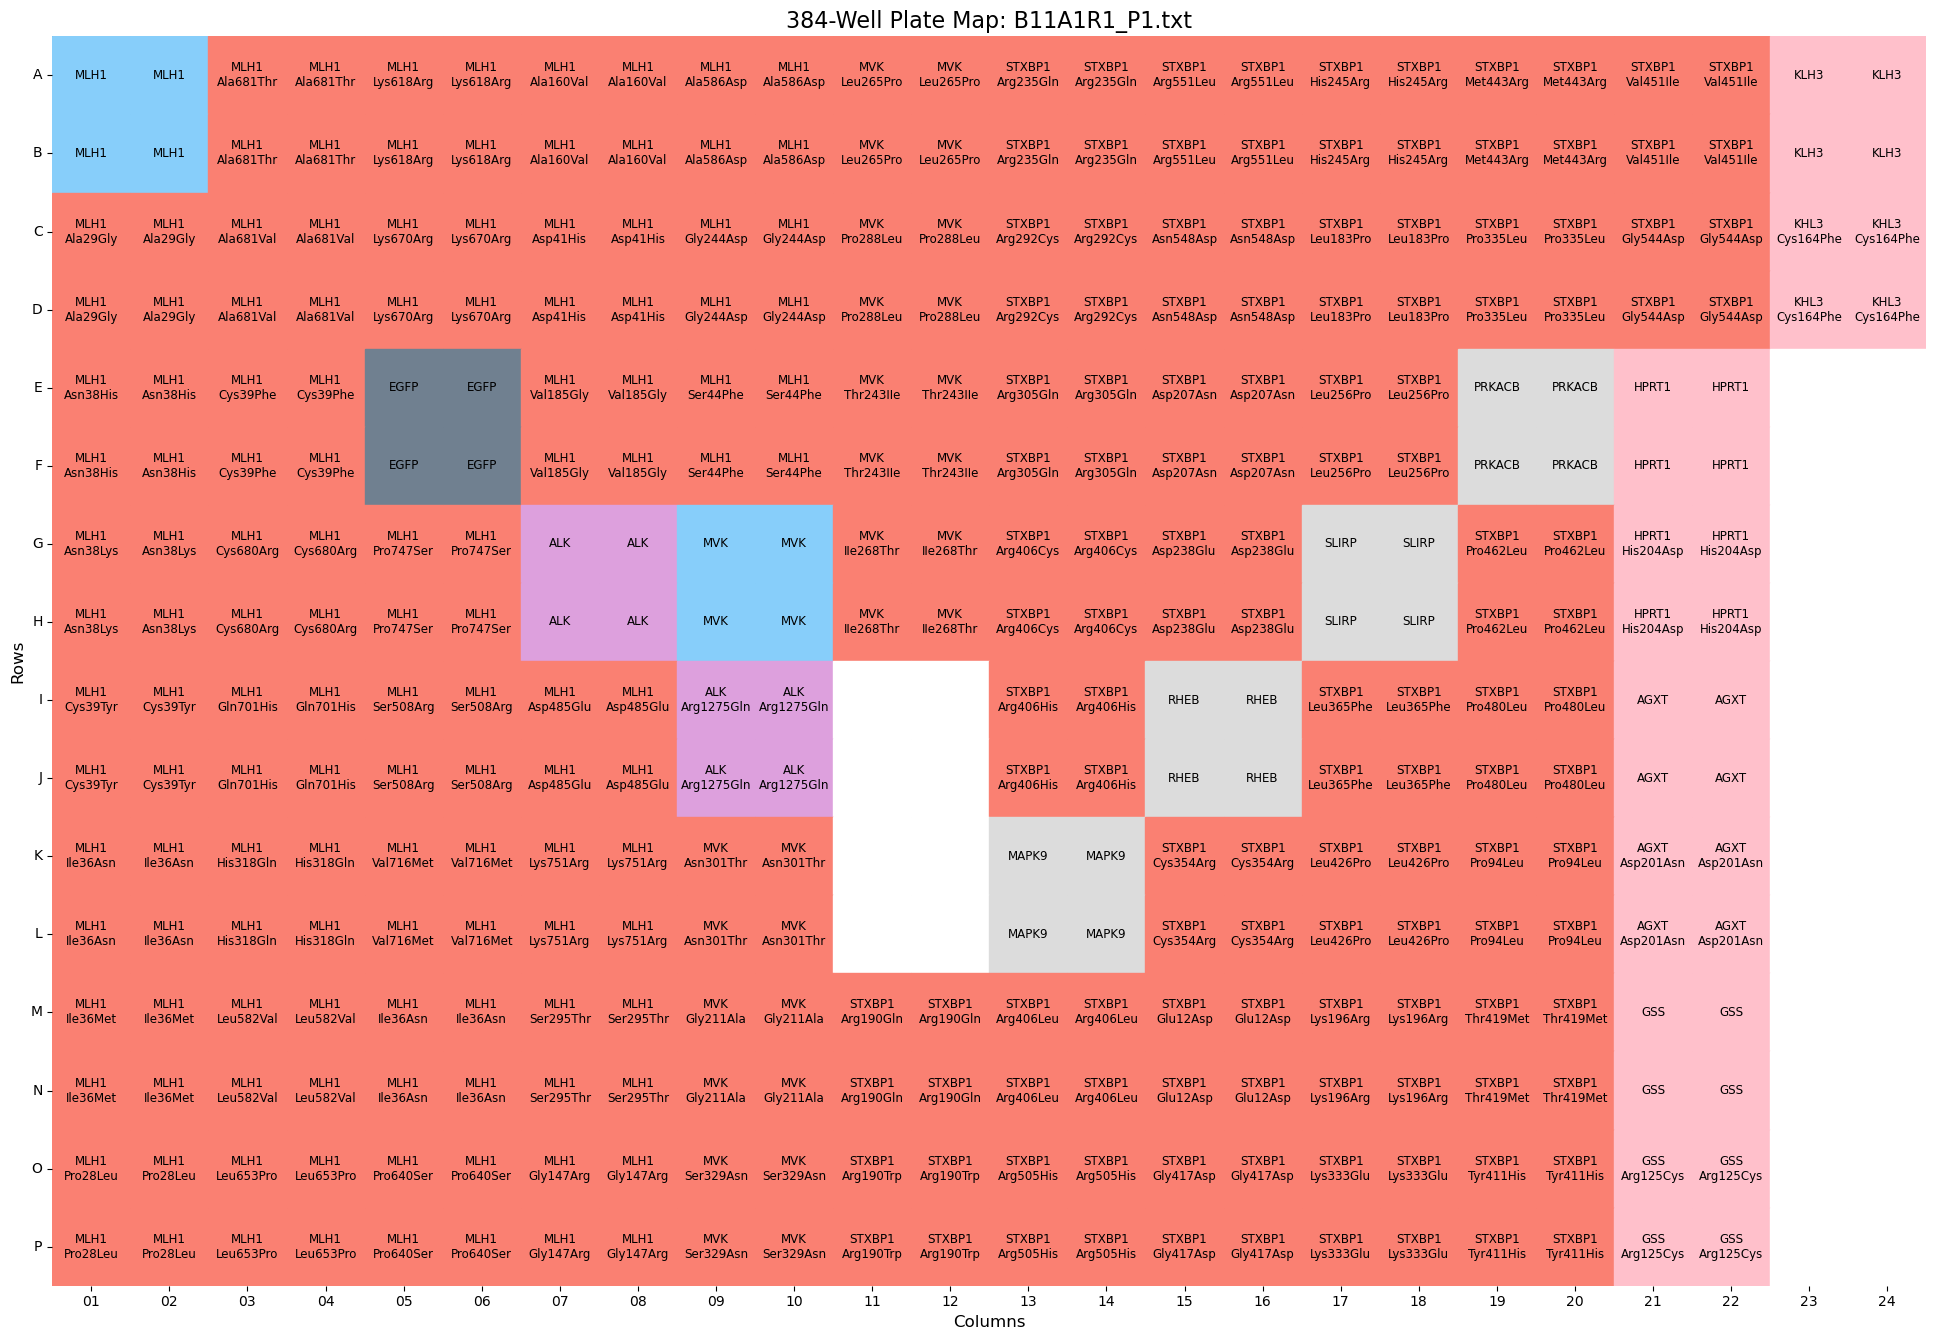

2024_12_09_Batch_12 B12A1R2_P1.txt
['disease_wt' 'allele' 'TC' 'PC' nan 'NC' 'cPC']
Final Symbol and Final Gene are the same:  False
Mismatch between Final Symbol and Final Gene: 


,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,...,notes,plate,quad,c96,r96,r384,c384,r384_letter,gene_symbol,symbol_original
18,B12A1R2_P1,E05,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,1,3,3,5,5,E,EGFP,NaN
89,B12A1R2_P1,C23,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,1,12,2,3,23,C,KHL3,KLH3
108,B12A1R2_P1,E06,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,2,3,3,5,6,E,EGFP,NaN
179,B12A1R2_P1,C24,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,2,12,2,3,24,C,KHL3,KLH3
198,B12A1R2_P1,F05,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,3,3,3,6,5,F,EGFP,NaN
269,B12A1R2_P1,D23,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,3,12,2,4,23,D,KHL3,KLH3
288,B12A1R2_P1,F06,NaN,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,4,3,3,6,6,F,EGFP,NaN
359,B12A1R2_P1,D24,KLH3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,4,12,2,4,24,D,KHL3,KLH3


,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,...,notes,plate,quad,c96,r96,r384,c384,r384_letter,gene_symbol,symbol_original
18,B12A1R2_P1,E05,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,1,3,3,5,5,E,EGFP,NaN
45,B12A1R2_P1,K11,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,1,6,6,11,11,K,NaN,NaN
89,B12A1R2_P1,C23,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,1,12,2,3,23,C,KHL3,KLH3
108,B12A1R2_P1,E06,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,2,3,3,5,6,E,EGFP,NaN
135,B12A1R2_P1,K12,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,2,6,6,11,12,K,NaN,NaN
179,B12A1R2_P1,C24,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,2,12,2,3,24,C,KHL3,KLH3
198,B12A1R2_P1,F05,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,3,3,3,6,5,F,EGFP,NaN
225,B12A1R2_P1,L11,NaN,NaN,NaN,NaN,NaN,1%_rescreen_P01_R1,F06,46,...,NaN,1,3,6,6,12,11,L,NaN,NaN
269,B12A1R2_P1,D23,KHL3,KHL3_Cys164Phe,594 Controls,NaN,NaN,1%_rescreen_P01_R1,B12,90,...,NaN,1,3,12,2,4,23,D,KHL3,KLH3
288,B12A1R2_P1,F06,EGFP,EGFP,561 Controls,NaN,NaN,1%_rescreen_P01_R1,C03,19,...,NaN,1,4,3,3,6,6,F,EGFP,NaN


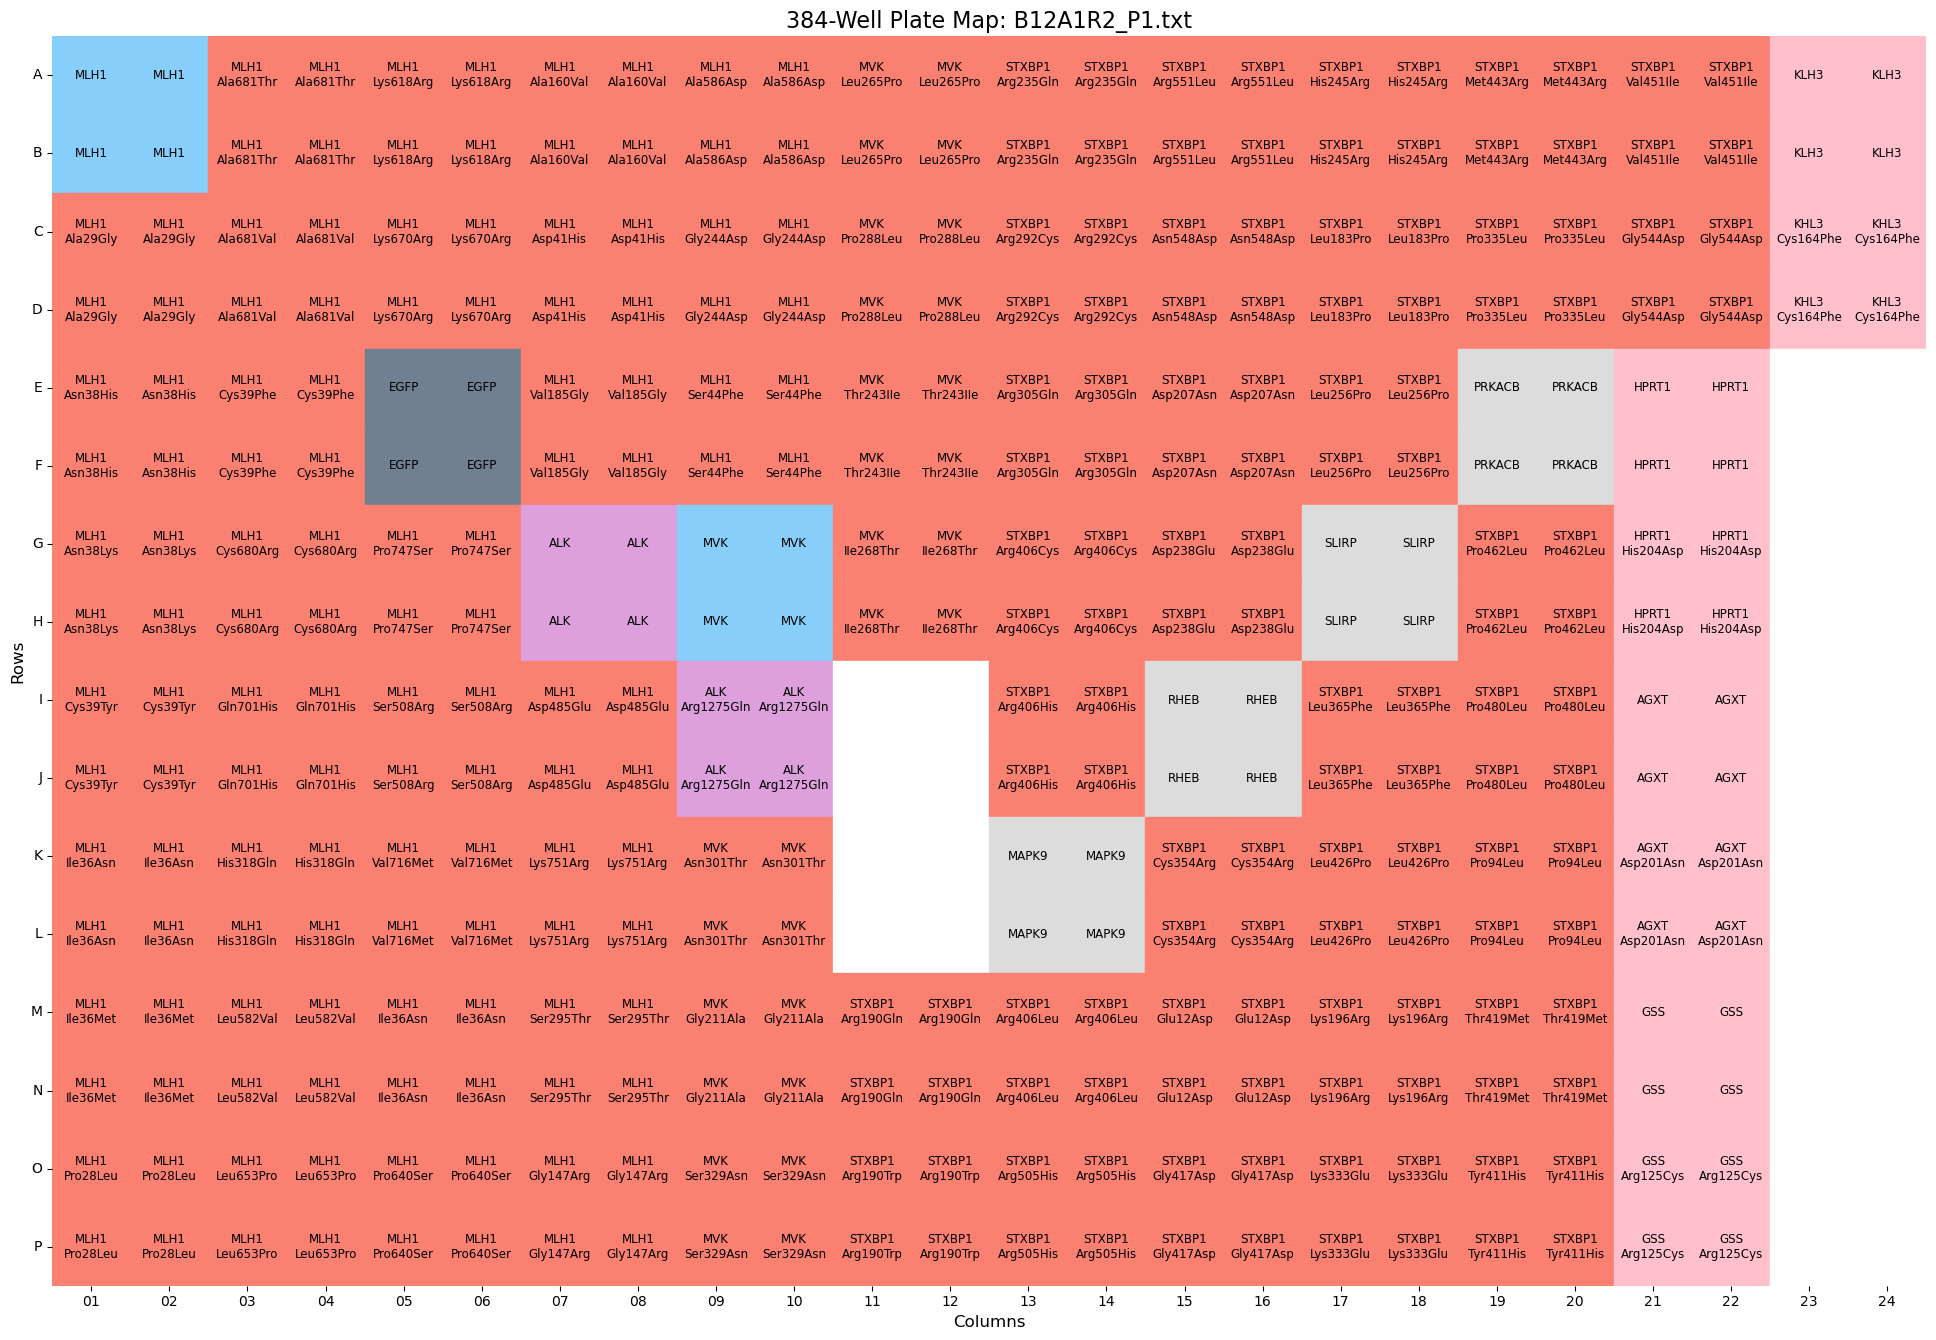

In [7]:
for batch in BIO_REP_BATCHES:
    for plate_map in os.listdir(INPUT_DIR.format(batch)):
        print(batch, plate_map)
        meta_data_df = pd.read_csv(Path(INPUT_DIR.format(batch)) / Path(plate_map), sep='\t')
        ## imaging well matched up
        assert(all(meta_data_df["well_position"]==meta_data_df["imaging_well"]))

        ## remove unwanted chars
        meta_data_df["symbol"] = meta_data_df["symbol"].str.replace(r"[^a-zA-Z0-9_]", "", regex=True)
        meta_data_df["gene_allele"] = meta_data_df["gene_allele"].str.replace(r"[^a-zA-Z0-9_]", "", regex=True)
        meta_data_df["node_type"] = meta_data_df["node_type"].str.replace(r"[^a-zA-Z0-9_]", "", regex=True)
        meta_data_df.loc[:,"gene_symbol"] = meta_data_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
        meta_data_df.loc[:,"symbol_original"] = meta_data_df.loc[:,"symbol"]
        print(meta_data_df["node_type"].unique())

        # print(meta_data_df["node_type"].unique())
        ## for checking name matching only, still need to KEEP ALL WELLS no matter if they have final_gene_allele or not
        meta_data_df_allele = meta_data_df[meta_data_df["gene_allele"].notna()]#.copy()
        ## check node_type
        print("Final Symbol and Final Gene are the same: ", all(meta_data_df_allele["symbol"] == meta_data_df_allele["gene_symbol"]))
        print("Mismatch between Final Symbol and Final Gene: ")
        display(meta_data_df_allele[meta_data_df_allele["symbol_original"] != meta_data_df_allele["gene_symbol"]])

        meta_data_df.loc[meta_data_df["gene_allele"]=="EGFP", "symbol"] = meta_data_df.loc[meta_data_df["gene_allele"]=="EGFP", "gene_symbol"]
        meta_data_df.loc[meta_data_df["gene_allele"]=="KHL3_Cys164Phe", "symbol"] = meta_data_df.loc[meta_data_df["gene_allele"]=="KHL3_Cys164Phe", "gene_symbol"]
        meta_data_df.loc[meta_data_df["gene_allele"].isna(), "node_type"] = np.nan

        ## remove STXBP1 alleles due to mixed alleles with HMBS on DNA source plate
        meta_data_df.loc[meta_data_df["gene_allele"]=="STXBP1", "node_type"] = np.nan
        meta_data_df.loc[meta_data_df["gene_allele"]=="STXBP1", "symbol"] = np.nan
        meta_data_df.loc[meta_data_df["gene_allele"]=="STXBP1", "gene_allele"] = np.nan
        
        # display(meta_data_df[meta_data_df["well_position"]=="H06"].sort_values(by="well_position").head(20))
        # display(meta_data_df_allele[meta_data_df_allele["symbol_original"] != meta_data_df_allele["gene_symbol"]])
        display(meta_data_df[meta_data_df["symbol_original"] != meta_data_df["gene_symbol"]])
        # print(meta_data_df.shape)

        plot_platemap(pl.DataFrame(meta_data_df), plate_name=plate_map)
        if not os.path.exists(Path(OUTPUT_DIR.format(batch))):
            os.makedirs(Path(OUTPUT_DIR.format(batch)))
        meta_data_df.to_csv(Path(OUTPUT_DIR.format(batch)) / Path(plate_map), sep='\t', index=False)

# pm_ref_df_1
# pm_ref_df_2

### Old damaged platemaps

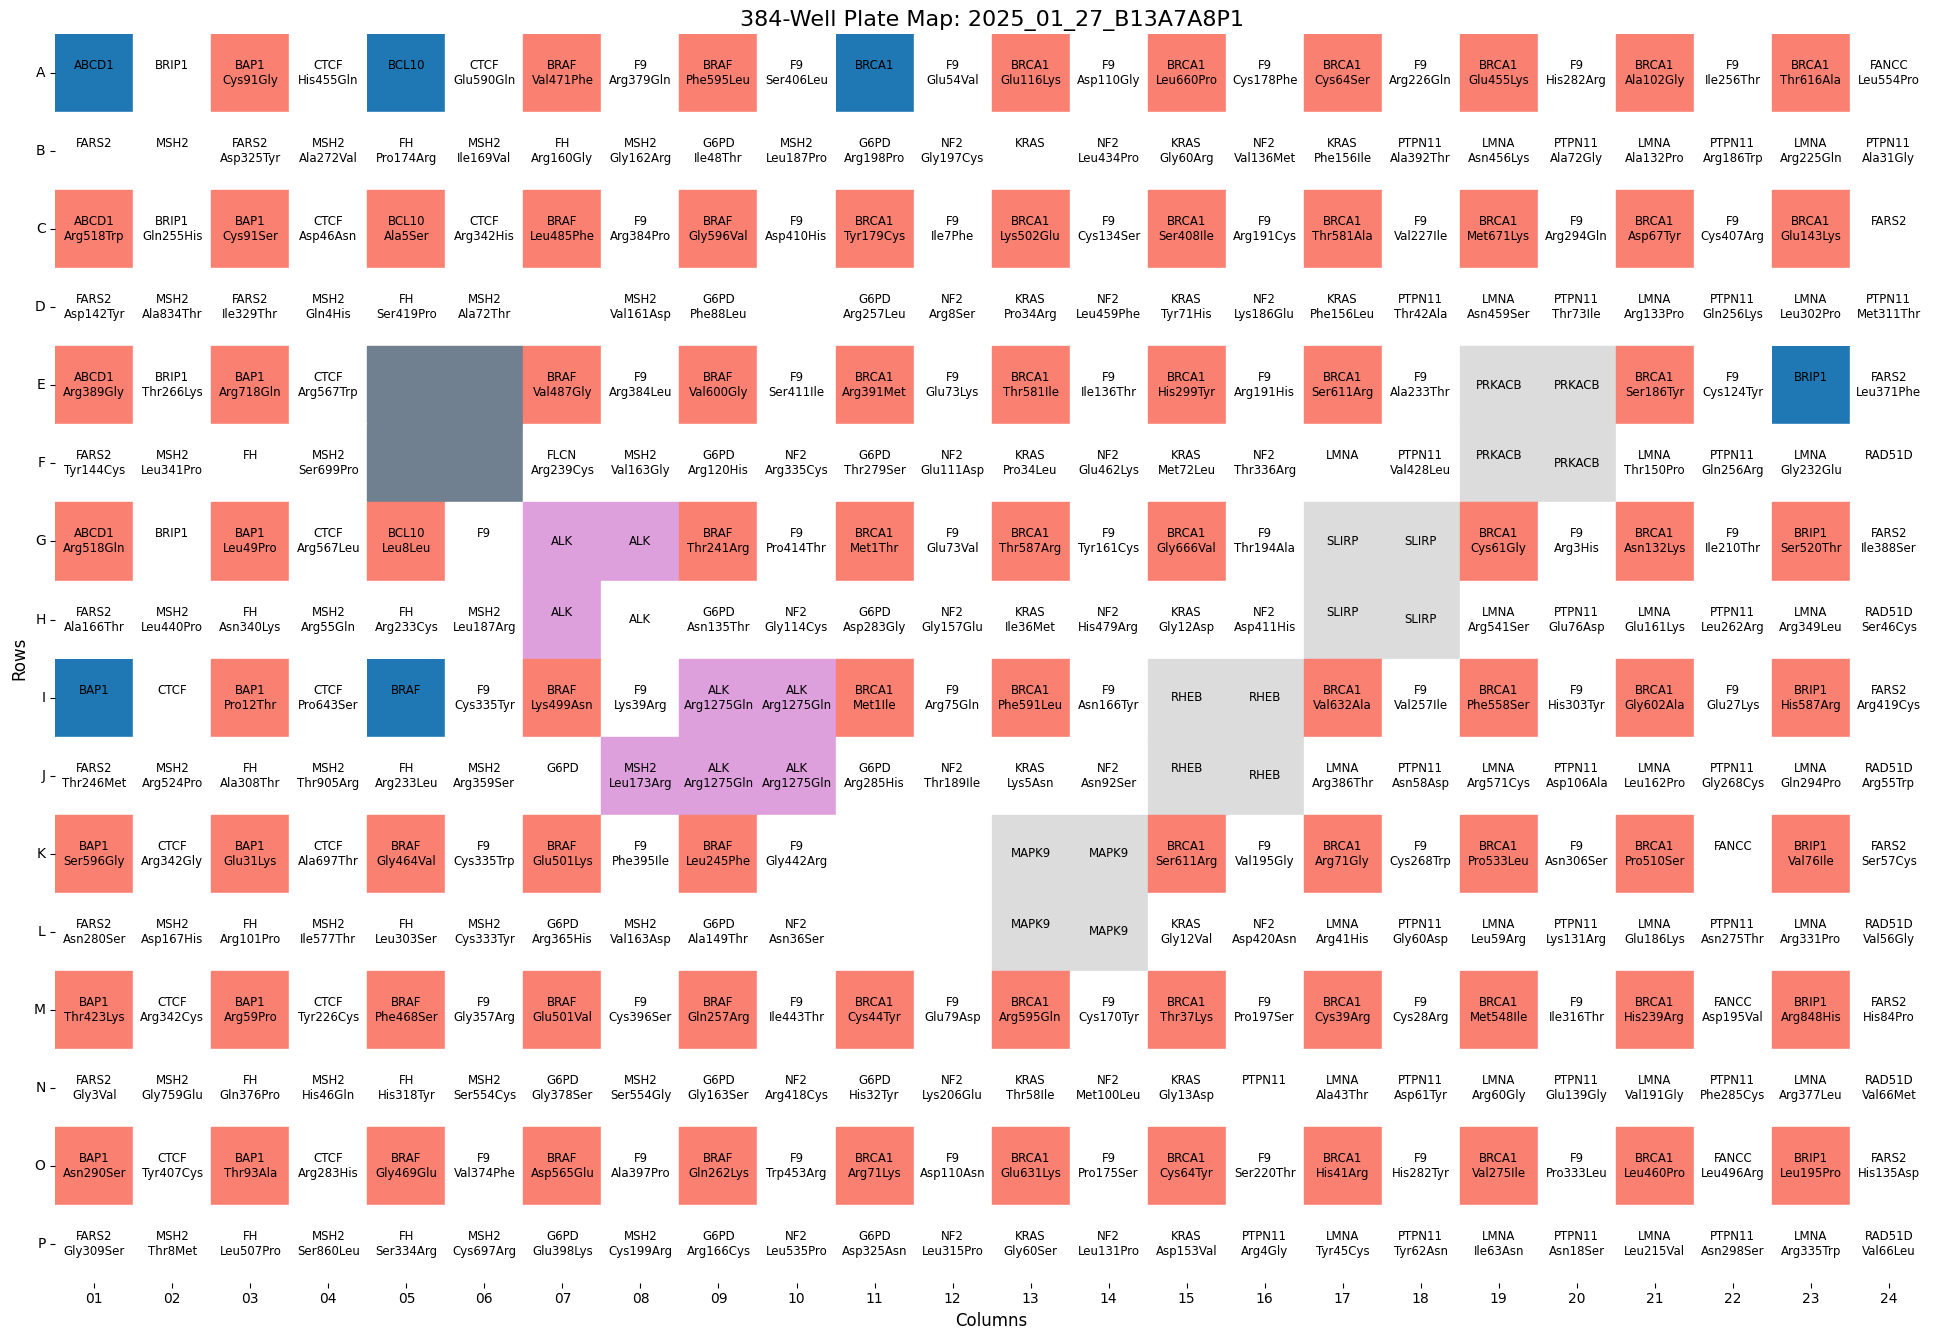

In [25]:
# batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P1_T1.txt"
plate_map = pl.read_csv(Path(batch_dir_13) / Path(plate_map_id), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

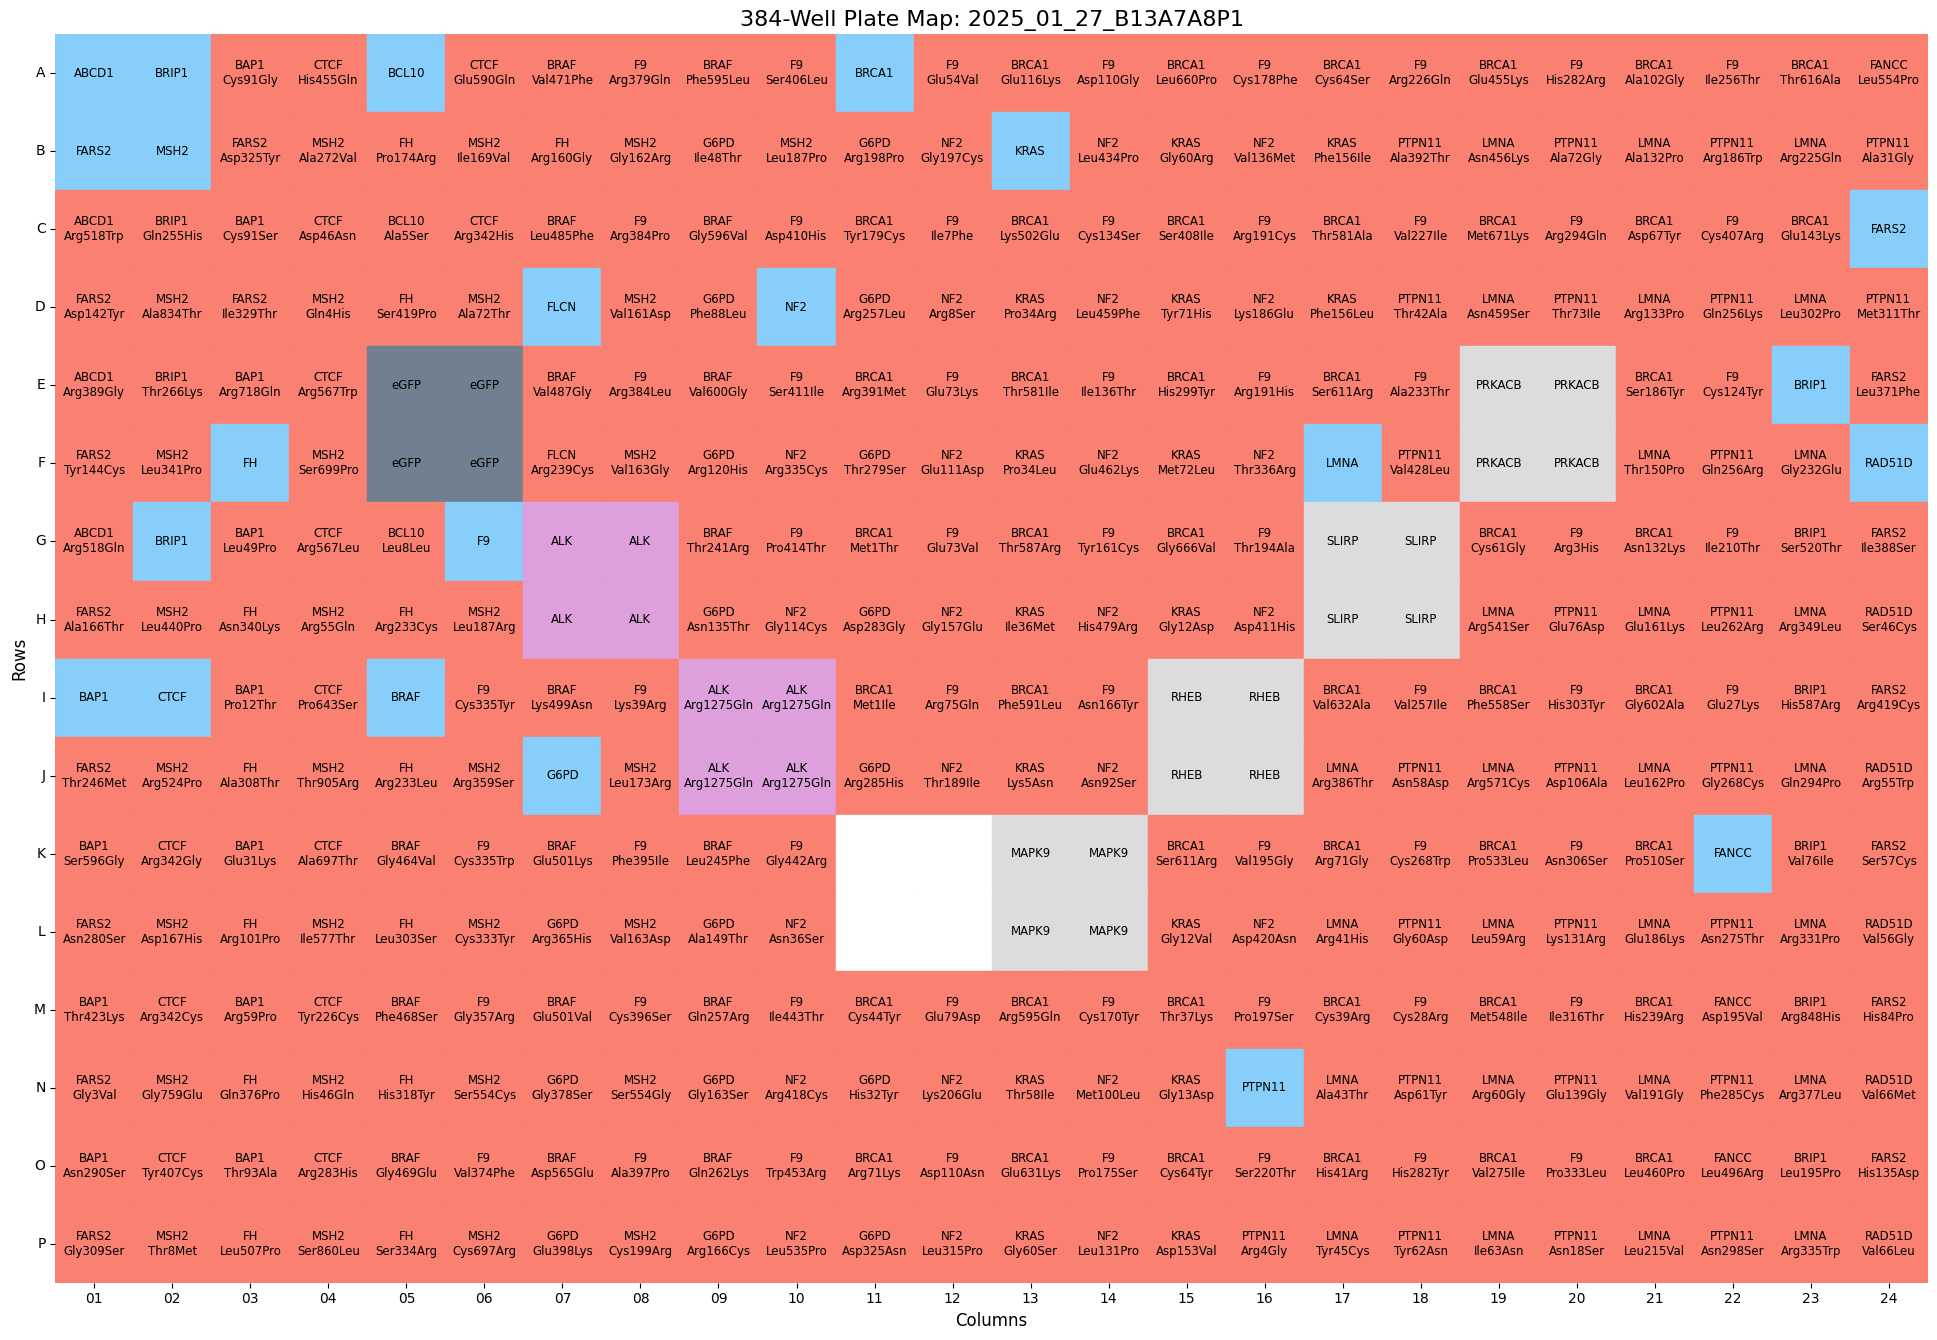

In [26]:
plate_map = plate_map.with_columns(
    # pl.col("symbol").alias("symbol_original"),
    # ## clean up the symbols first
    # pl.col("symbol").str.replace_all(r'[^a-zA-Z0-9]', '').alias("symbol"),
    # Condition 1: Keep "_" as is or fill the symbol if gene allele is missing by accident
    pl.when((pl.col("gene_allele")=="_")|(pl.col("gene_allele").is_null()&pl.col("symbol").is_not_null()))
        .then(pl.col("symbol"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.when((pl.col("gene_allele").is_in(PC))) #(pl.col("node_type").is_null())
        .then(pl.lit("PC"))
        .when((pl.col("gene_allele").is_in(NC))) #(pl.col("node_type").is_null())
        .then(pl.lit("NC"))
        # .when((pl.col("gene_allele").is_in(cPC))) #(pl.col("node_type").is_null())
        # .then(pl.lit("cPC"))
        .when(pl.col("aa_change").is_not_null()) ## manually handle a special case
        .then(pl.lit("allele"))
        .when((pl.col("aa_change").is_null())&(pl.col("symbol").is_not_null())&(~pl.col("symbol").is_in(PC))&(~pl.col("symbol").is_in(NC))&(~pl.col("symbol").str.to_uppercase().is_in(TC))) ## (pl.col("node_type").is_null())&
        .then(pl.lit("disease_wt"))
        .when(pl.col("node_type").is_not_null())
        .then(pl.col("node_type"))
        .when((pl.col("symbol").str.to_uppercase().is_in(TC))) #(pl.col("node_type").is_null())
        .then(pl.lit("TC"))
        .alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

In [27]:
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")

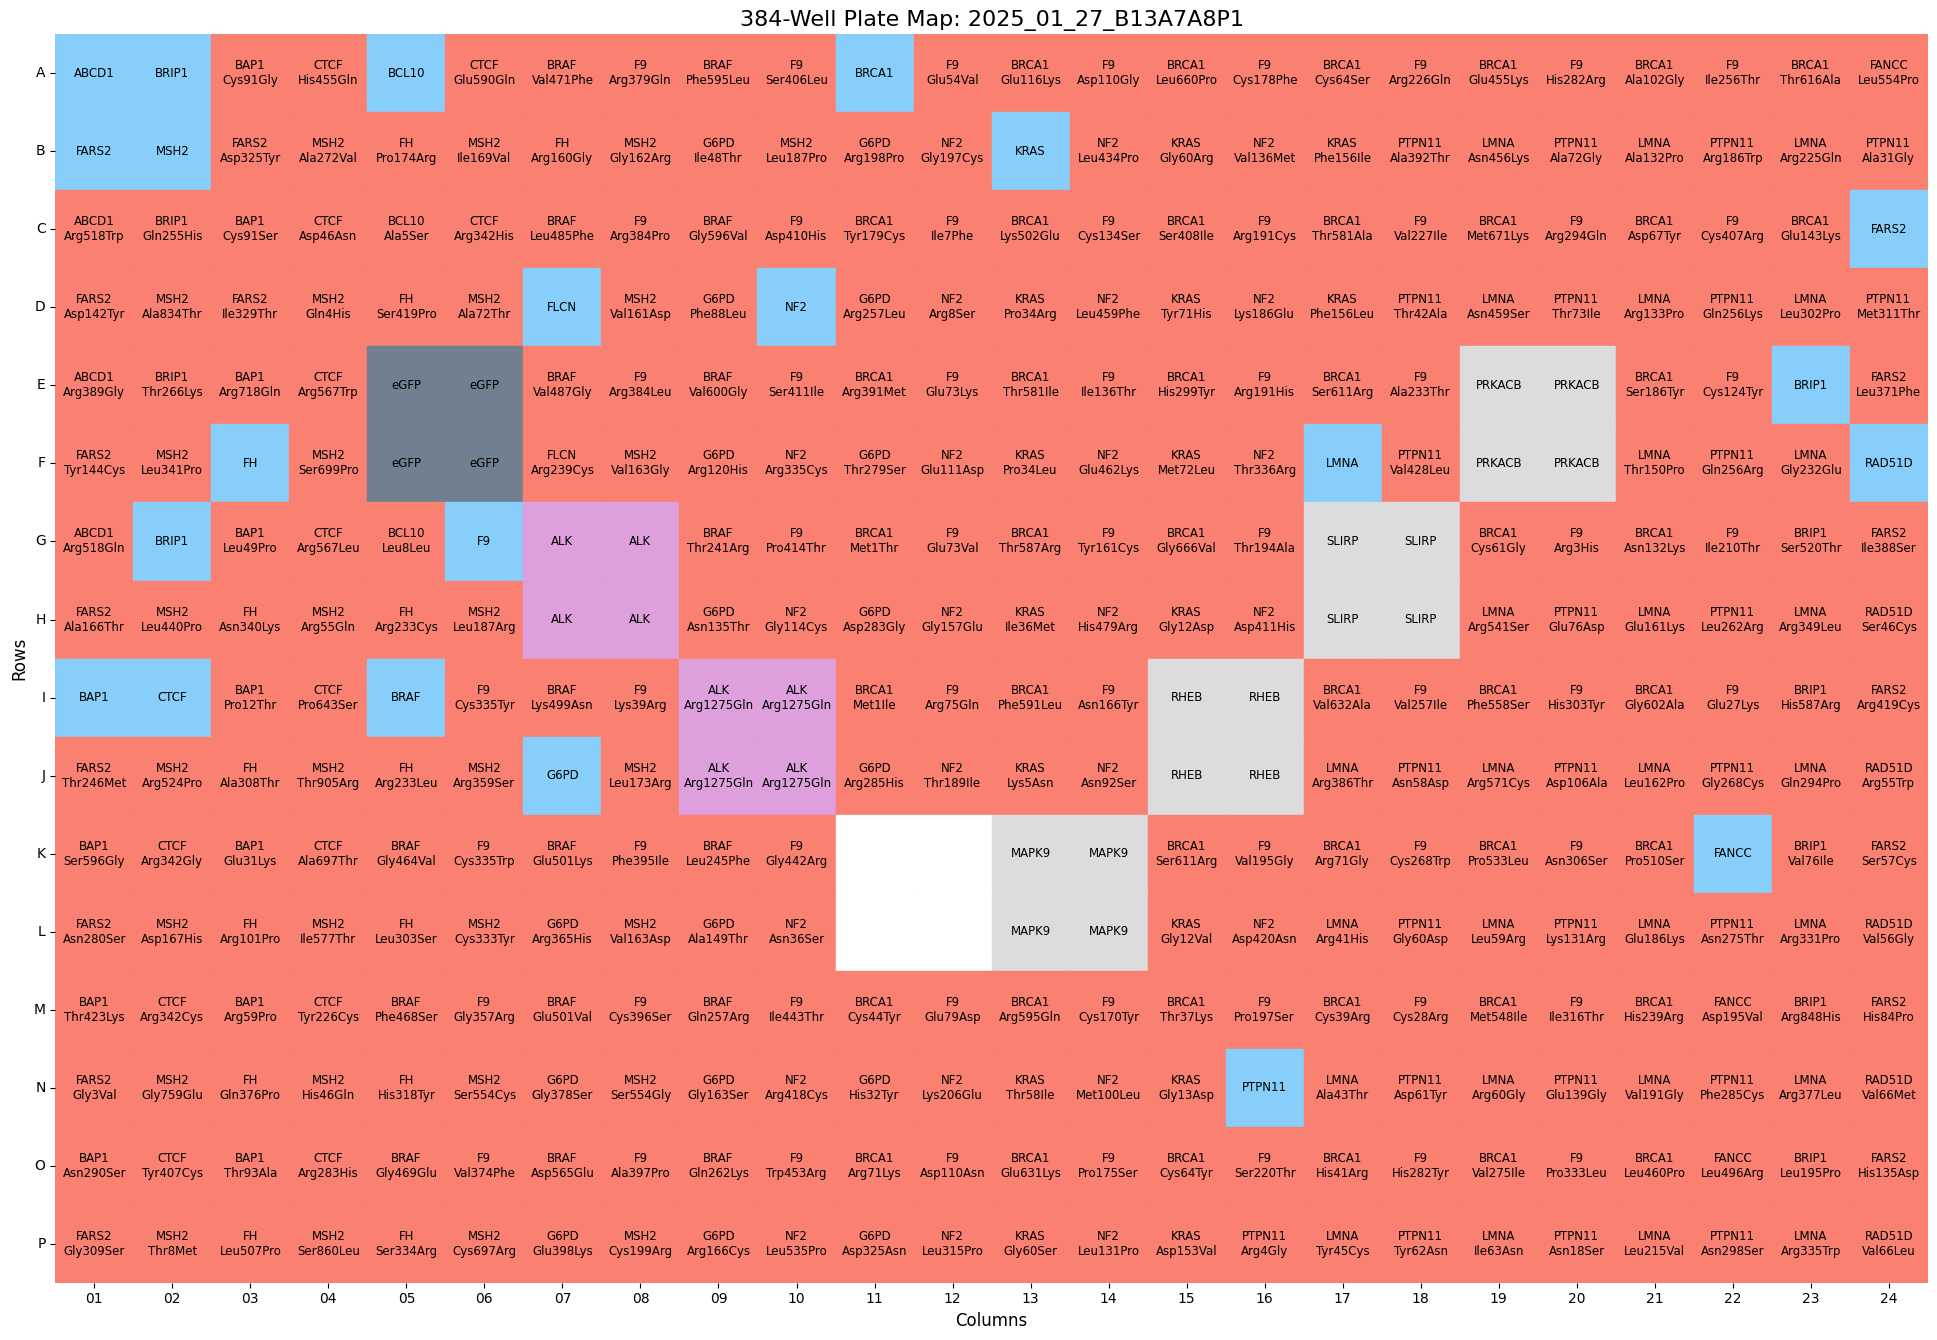

In [4]:
# plate_map.filter(pl.col("well_position")=="E19")
# plate_map.filter(pl.col("well_position")=="E19")
# plate_map.filter(pl.col("symbol")=="FLCN")
# plate_map.filter(pl.col("symbol").str.to_uppercase().is_in(TC))

batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P1_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

### Second plate

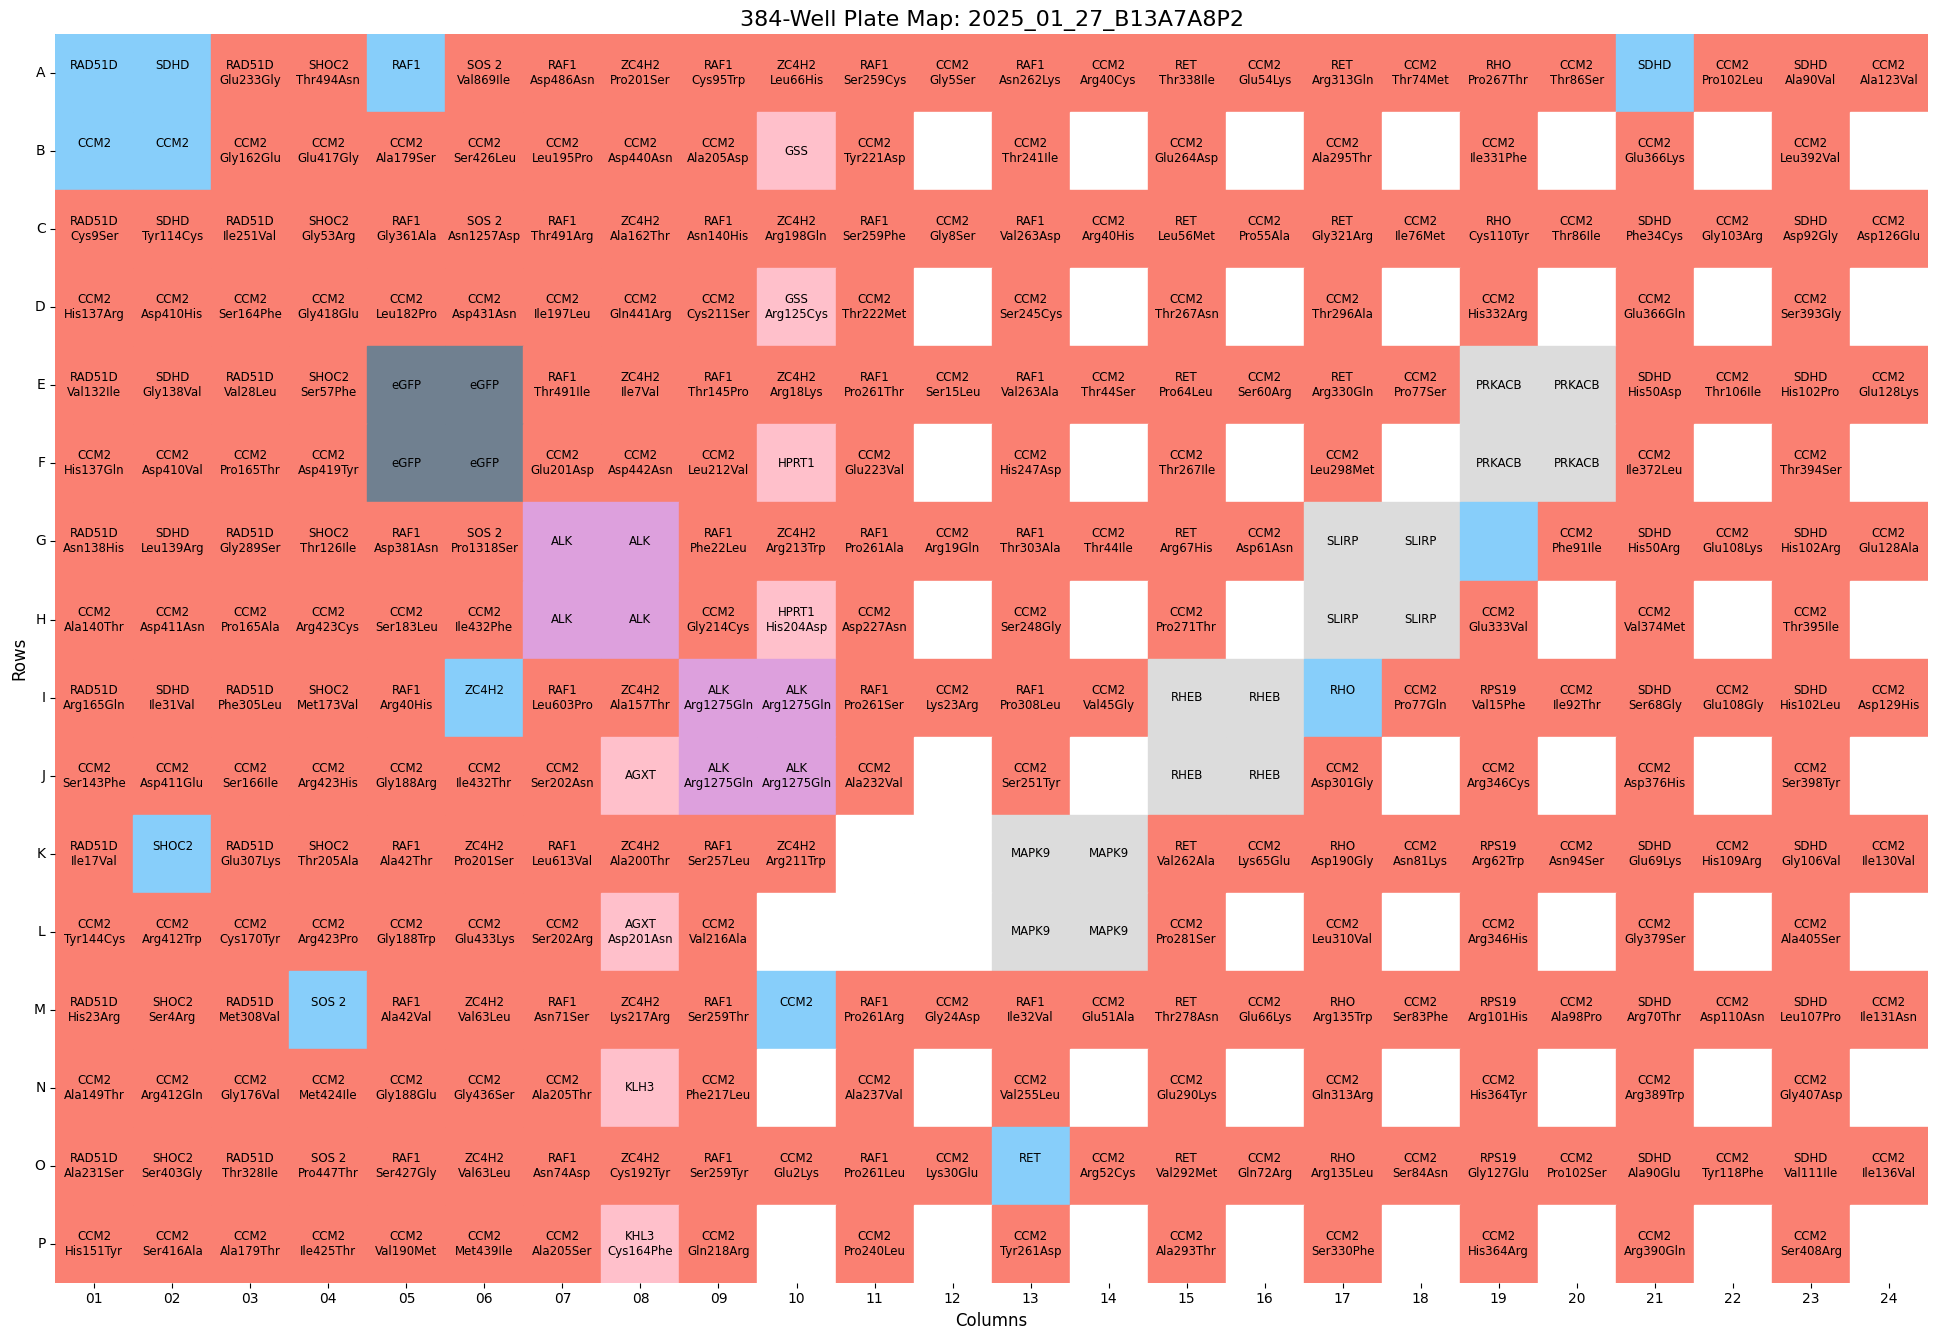

In [24]:
batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2025_01_27_Batch_13/platemap/"

# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P2_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

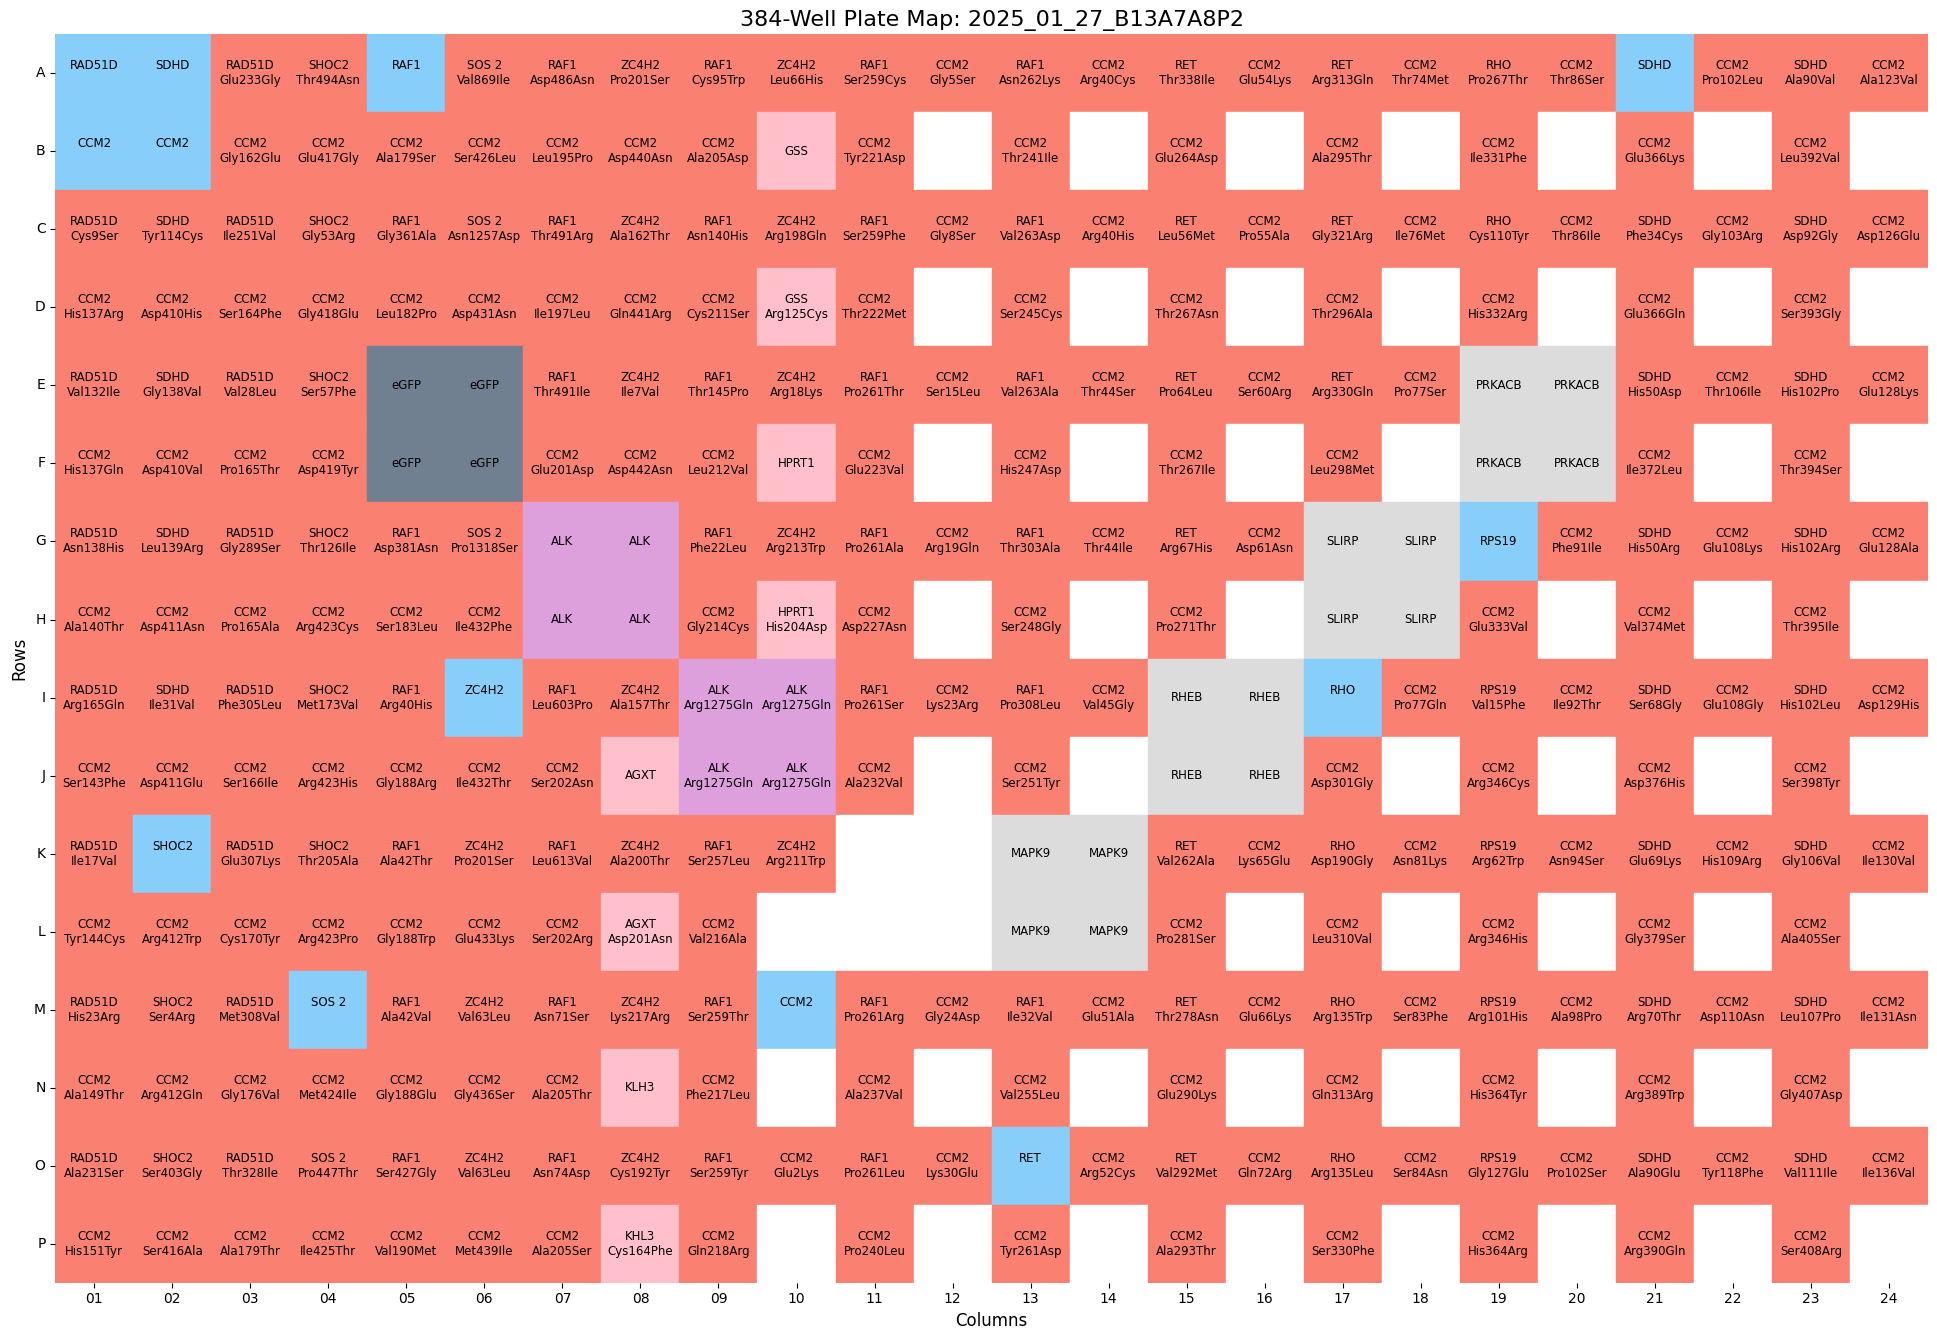

In [5]:
batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P2_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

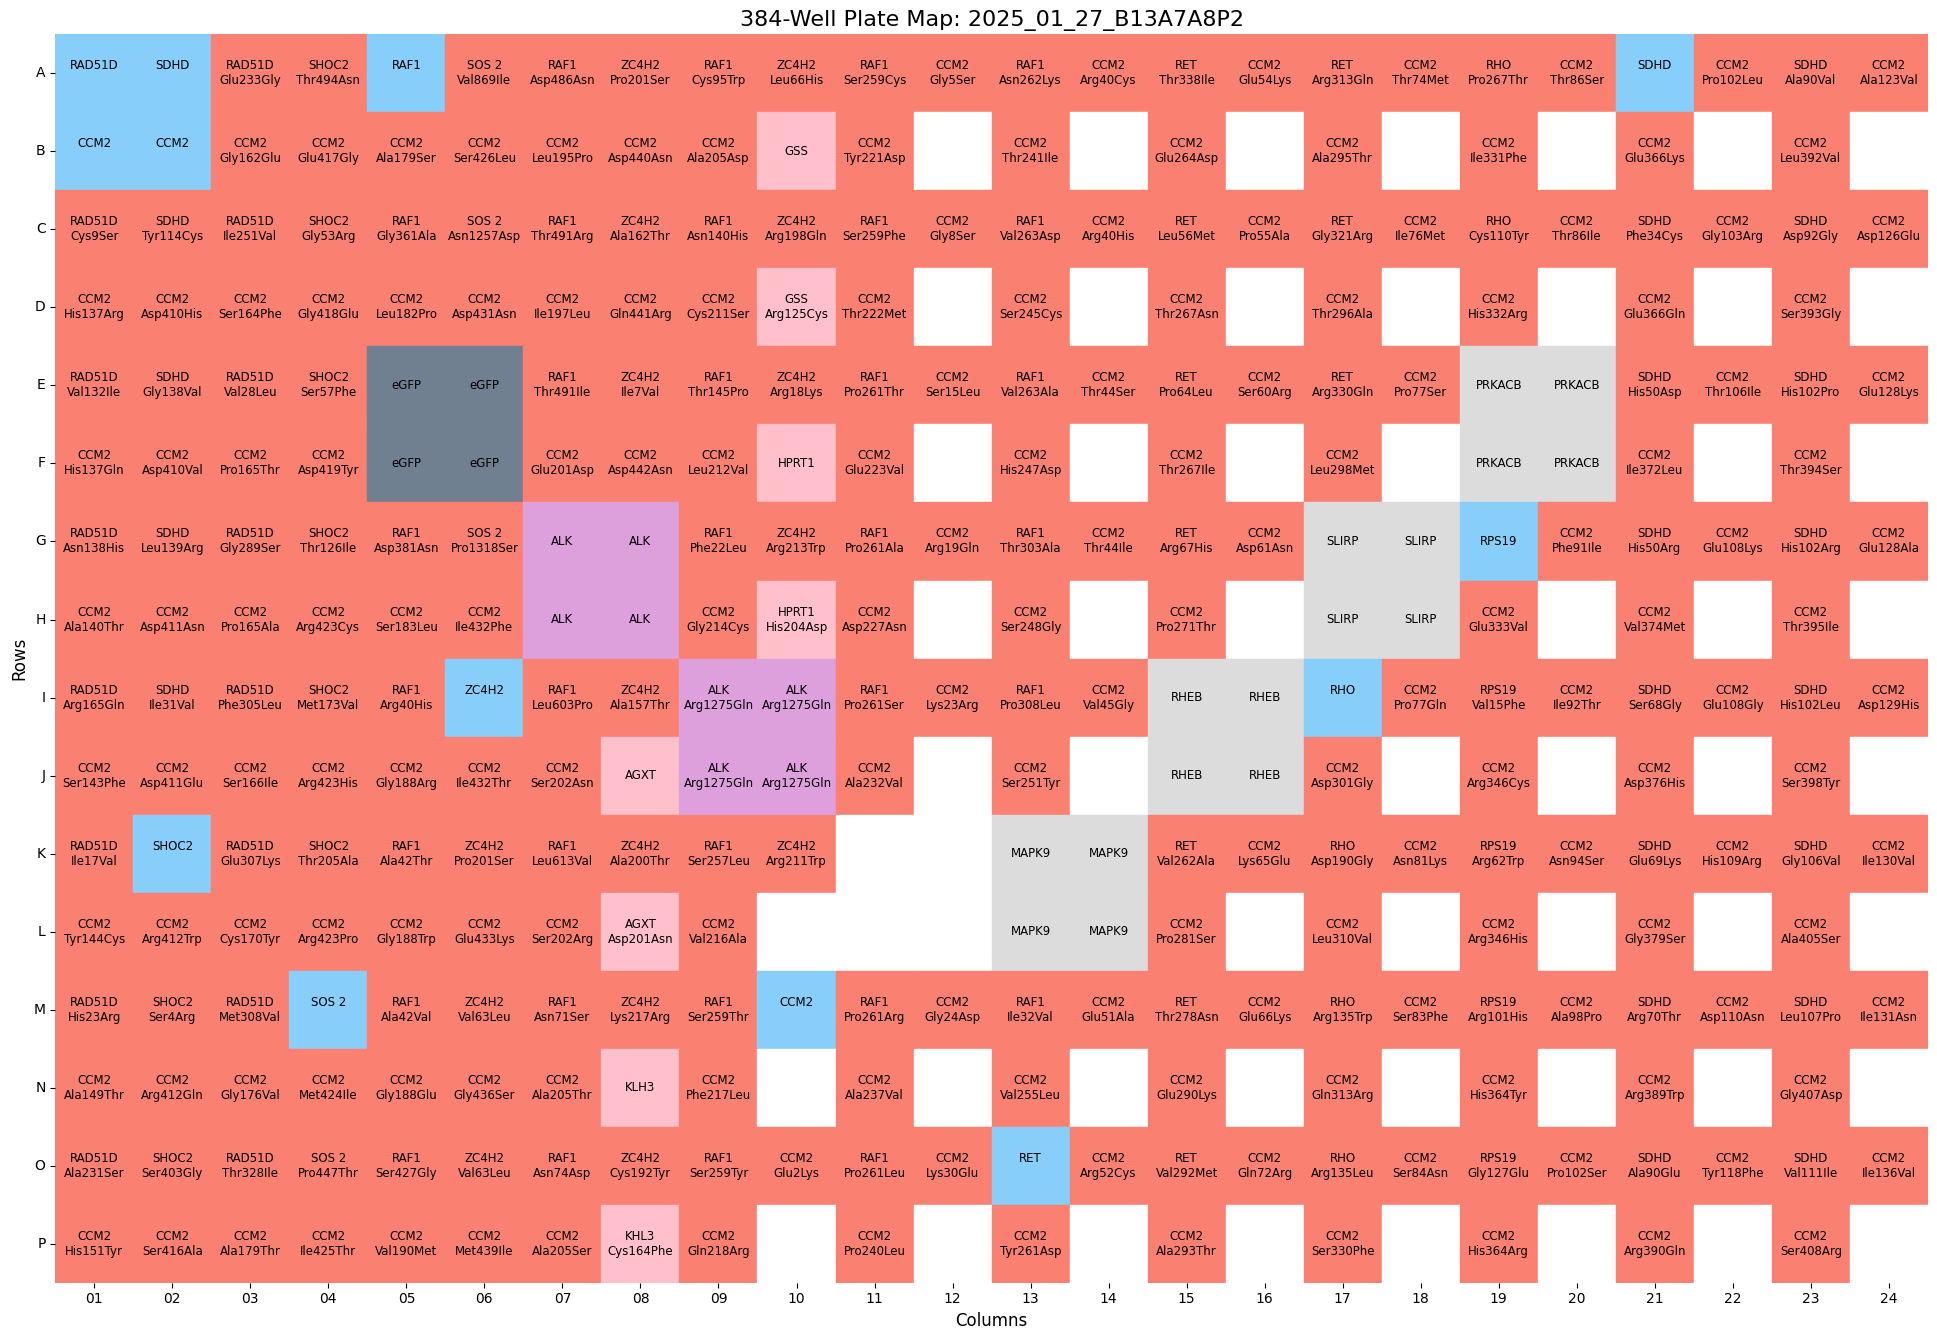

In [18]:
plate_map = plate_map.with_columns(
    # Condition 1: Keep "_" as is or fill the symbol if gene allele is missing by accident
    pl.when(pl.col("symbol").is_not_null()&pl.col("gene_allele").is_null())
        .then(pl.col("symbol"))
        .otherwise(pl.col("gene_allele"))
        .alias("gene_allele")
    # pl.when((pl.col("gene_allele")=="_")|(pl.col("gene_allele").is_null()&pl.col("symbol").is_not_null()))
    #     .then(pl.col("symbol"))
    #     .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
    #     .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
    #     .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
    #     .alias("gene_allele"),  # Replace the original column,
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.col("gene_allele"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
    #     .otherwise(pl.col("gene_allele"))
    #     .alias("symbol"),
    # pl.when(pl.col("aa_change").is_not_null()) ## manually handle a special case
    #     .then(pl.lit("allele"))
    #     .when((pl.col("node_type").is_null())&(pl.col("aa_change").is_null())&(pl.col("symbol").is_not_null())&(~pl.col("symbol").is_in(PC)))
    #     .then(pl.lit("disease_wt"))
    #     .when((pl.col("node_type").is_null())&(pl.col("symbol").is_in(PC)))
    #     .then(pl.lit("PC"))
    #     # .when(pl.col("node_type").is_not_null())
    #     # .then(pl.col("node_type"))
    #     .alias("control_type")
)
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

In [21]:
# plate_grid.filter(pl.col("well_position")=="G19")

In [22]:
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P2_T1.txt", separator="\t")

## Batch 9/10

### Confocal

Number of unique alleles: ['EGFP', 'F9_Glu27Lys', 'ALK_Arg1275Gln', 'PRKACB', 'LMNA', 'CTCF_Tyr226Cys', 'RPS19', 'RPS19_Val15Phe', 'CTCF_His455Gln', 'LMNA_Arg349Leu', 'G6PD_Glu398Lys', 'BCL10_Leu8Leu', 'F9_Glu73Val', 'G6PD', 'F9_Trp453Arg', 'FLCN_Arg239Cys', 'RPS19_Arg62Trp', 'LMNA_Arg331Pro', 'LMNA_Arg60Gly', 'FANCC_Asp195Val', 'LMNA_Glu186Lys', 'CTCF_Ala697Thr', 'F9_Pro333Leu', 'F9_Cys396Ser', '_', 'F9_Arg294Gln', 'RPS19_Arg101His', 'LMNA_Thr150Pro', 'F9_Ile256Thr', 'MRE11', 'MAPK9', 'F9_Cys170Tyr', 'F9_Gly357Arg', 'F9_Cys28Arg', 'CTCF_Arg342Cys', 'CTCF', 'CTCF_Asp46Asn', 'SLIRP', 'F9_Arg191His', 'F9_Cys268Trp', 'FANCC_Leu554Pro', 'CTCF_Glu590Gln', 'MRE11_Arg202Gly', 'LMNA_Tyr45Cys', 'LMNA_Ala132Pro', 'RPS19_Gly127Glu', 'CTCF_Arg342His', 'CTCF_Arg567Leu', 'CTCF_Arg342Gly', 'F9_Glu73Lys', 'CTCF_Tyr407Cys', 'F9_Arg384Pro', 'FANCC', 'F9_Arg226Gln', 'ALK', 'F9_Asp110Asn', 'LMNA_Arg541Ser', 'F9_Asp410His', 'LMNA_Gly232Glu', 'F9_His303Tyr', 'LMNA_Arg571Cys', 'F9_Asn306Ser', 'LMNA_Ala43Thr'

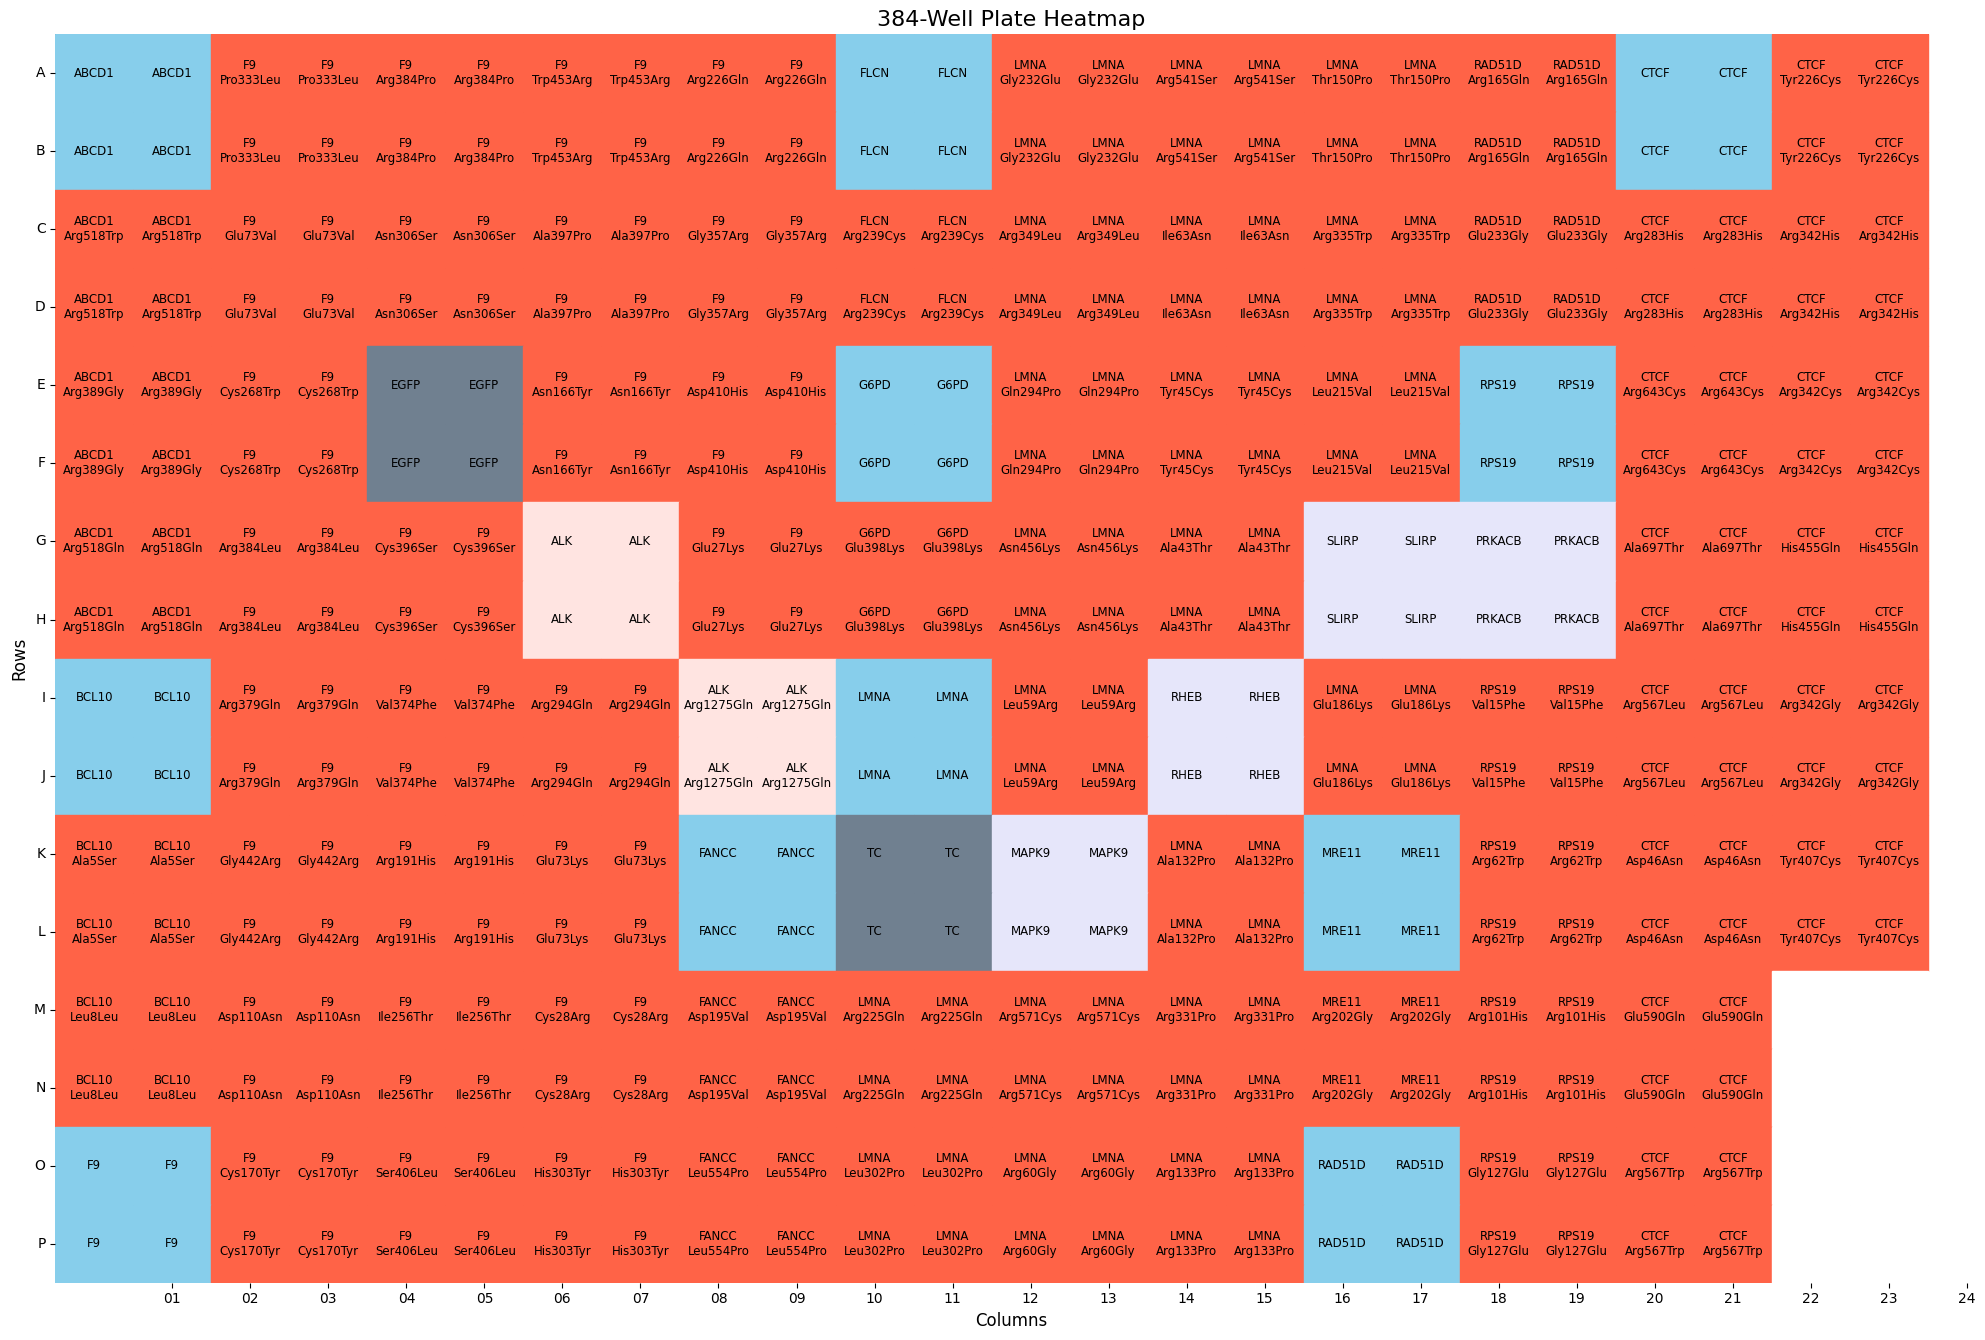

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P01""","""A01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T1""","""A01""",1,"""A01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,1,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
1,"""01""","""""","""B""","""01""","""P01""","""B01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T3""","""A01""",1,"""B01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,3,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
2,"""01""","""""","""C""","""01""","""P01""","""C01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T1""","""B01""",2,"""C01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
3,"""01""","""""","""D""","""01""","""P01""","""D01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T3""","""B01""",2,"""D01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",3,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
4,"""01""","""""","""E""","""01""","""P01""","""E01""","""ABCD1""","""ABCD1_Arg389Gly""","""CAVA_CP_P01_Prep2""","""C01""",3,"""CAVA_CP_Array_P01_T1""","""C01""",3,"""E01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007023""","""1165C>G""","""Arg389Gly""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg389Gly"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""","""P01""","""L24""","""CTCF""","""CTCF_Tyr407Cys""","""CAVA_CP_P02""","""H04""",32,"""CAVA_CP_Array_P01_T4""","""F12""",94,"""L24""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",6173,"""CCSBVarC010870""","""1220A>G""","""Tyr407Cys""",4,6,1,9,10,594,"""allele""","""allele""","""CTCF Tyr407Cys"""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [36]:
batch9_platemap_confo = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_confocal/platemap"
plate_map_id = "B9A6R1_P01.txt"
plate_map = pl.read_csv(Path(batch9_platemap_confo) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(~pl.all_horizontal(pl.all().is_null()))
# print(plate_map.shape

column_name = "gene_allele"
plate_map = plate_map.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)

# print(plate_map.select(pl.col(column_name).unique()))
# print(plate_map.select(pl.col("gene_allele").unique()))
# # print(plate_map.select(pl.col("symbol").unique()))
plot_platemap(plate_map)

(236, 24)
Number of unique alleles: ['NF2_Lys206Glu', 'NF2_Met29Ile', 'ZC4H2_Arg211Trp', 'ALK', 'NF2_Ser489Gly', 'ZC4H2_Arg198Gln', '_', 'NF2_Asn220Tyr', 'ZC4H2_Lys217Arg', 'NF2_Asn92Ser', 'NF2_Met100Leu', 'ZC4H2_IIe7Val', 'NF2_Leu459Phe', 'NF2_Arg471Gly', 'ZC4H2_Ala200Thr', 'ZC4H2_Arg67Gln', 'NF2_Val136Met', 'NF2_Asp420Asn', 'NF2_Leu434Pro', 'NF2_Leu535Pro', 'EGFP', 'NF2_Leu315Pro', 'NF2_Thr336Arg', 'NF2_Glu111Asp', 'ZC4H2_Ala157Thr', 'NF2_Pro410Leu', 'ZC4H2_Val63Leu', 'NF2_Glu462Lys', 'ZC4H2_Leu66His', 'ALK_Arg1275Gln', 'NF2_Glu344Ala', None, 'NF2_Gly157Glu', 'NF2_Arg335Cys', 'NF2_Leu58Pro', 'NF2_Asp411His', 'NF2_Arg418Cys', 'NF2_Lys186Glu', 'ZC4H2_Ala162Thr', 'NF2_Leu277Pro', 'NF2_Pro19Arg', 'ZC4H2_Cys192Tyr', 'NF2_Leu131Pro', 'NF2_Gln64Pro', 'NF2_Arg8Ser', 'ZC4H2', 'ZC4H2_Pro201Ser', 'NF2_Thr189Ile', 'NF2_Asn36Ser', 'NF2_Leu375Arg', 'MAPK9', 'NF2', 'ZC4H2_Arg18Lys', 'NF2_His479Arg', 'ZC4H2_Arg213Trp']


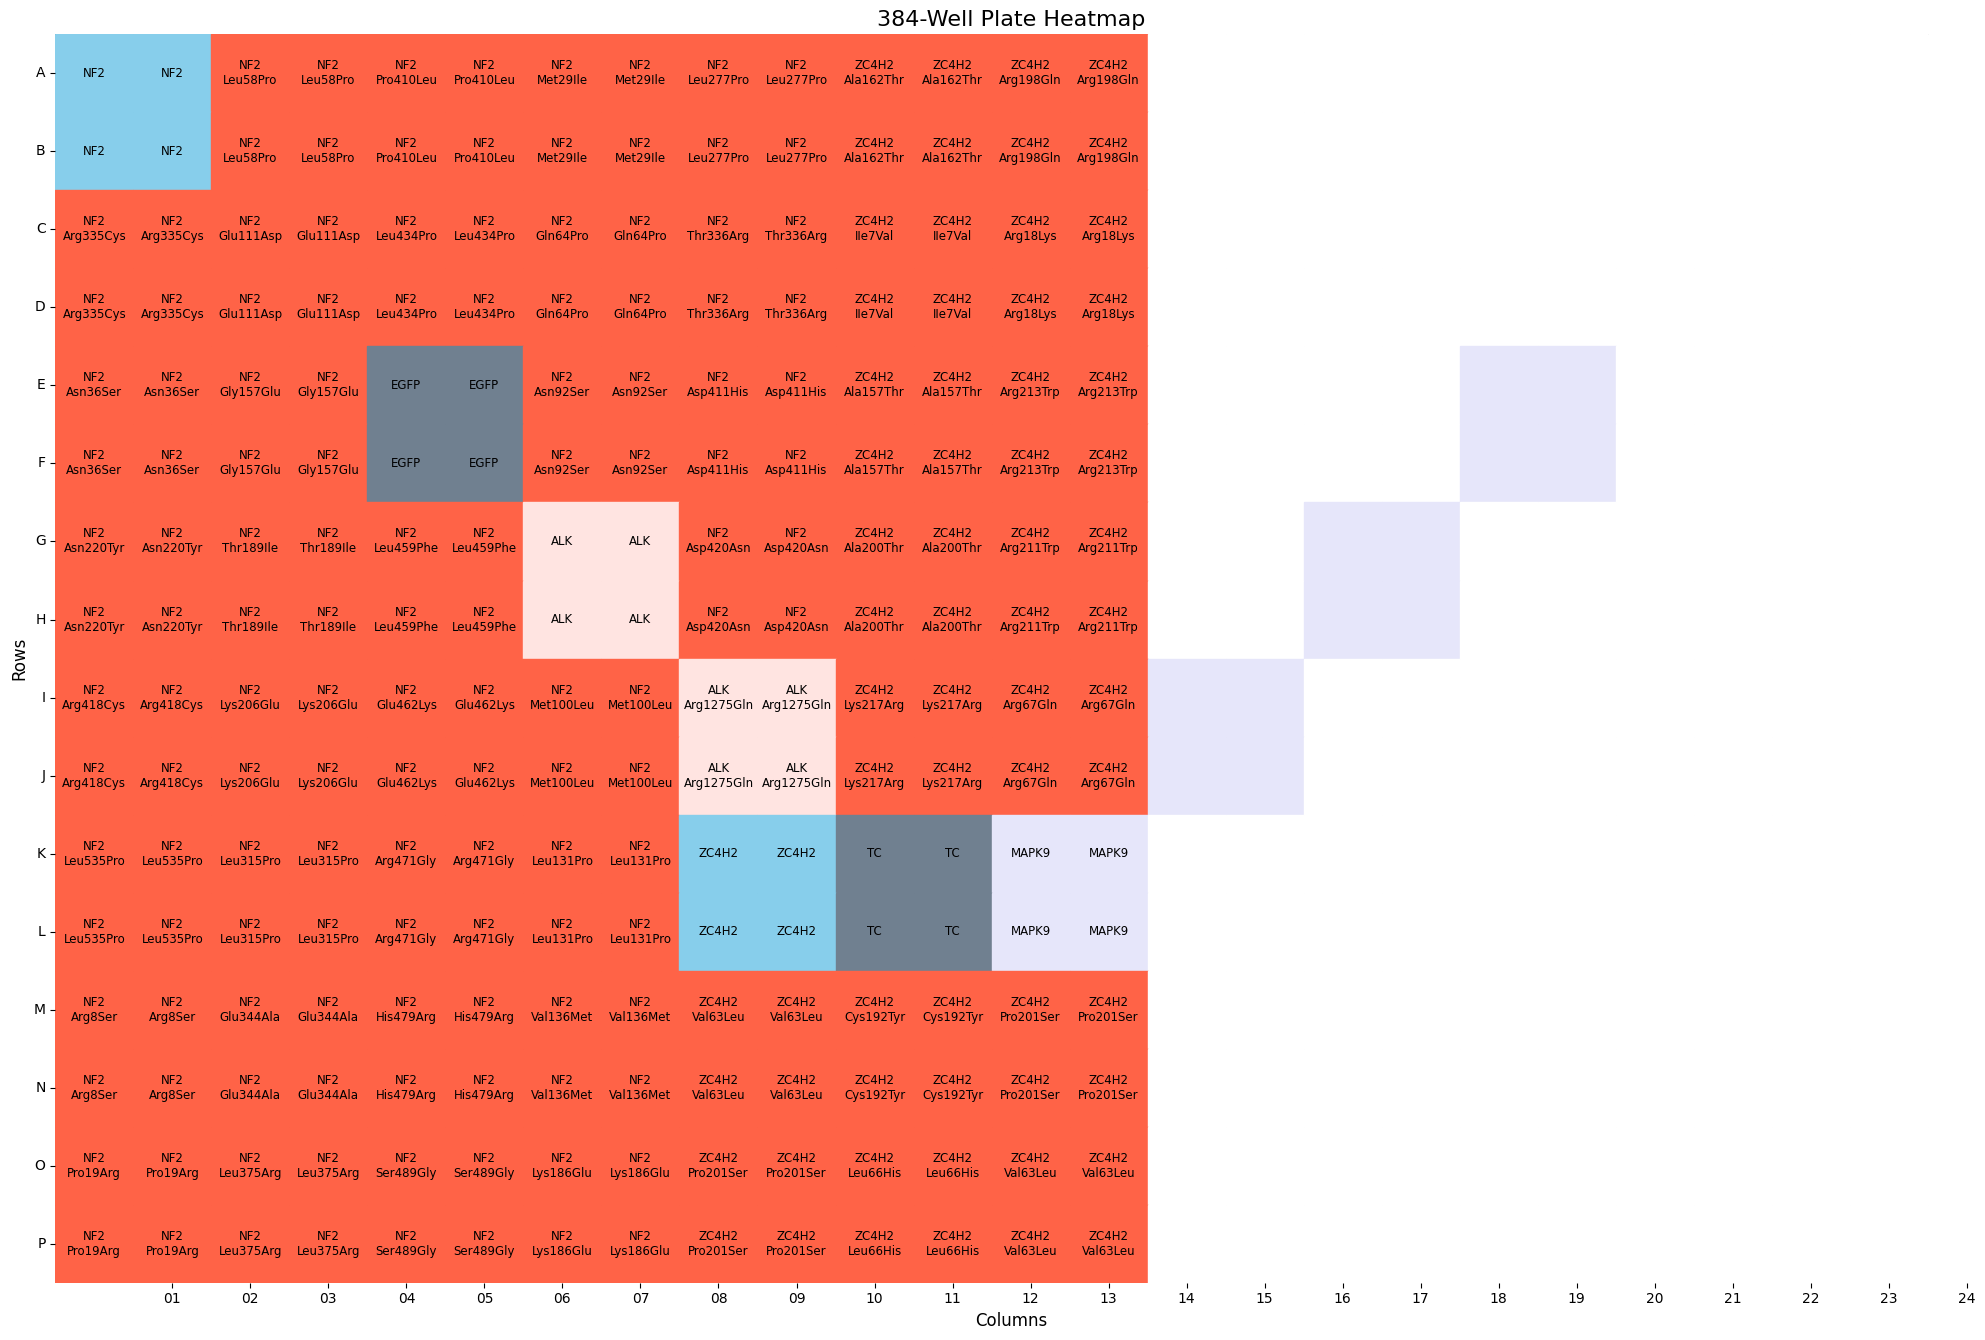

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P02""","""A01""","""NF2""","""NF2""","""CAVA_CP_P01_Prep2""","""B12""",90,"""CAVA_CP_Array_P02_T1""","""A01""",1,"""A01""","""B9A6R1_P2""","""B10A6R2_P2""","""disease_wt""",3697,null,null,null,1,6,2,9,10,594,"""disease_wt""","""disease_wt""","""NF2"""
1,"""01""","""""","""B""","""01""","""P02""","""B01""","""NF2""","""NF2""","""CAVA_CP_P01_Prep2""","""B12""",90,"""CAVA_CP_Array_P02_T3""","""A01""",1,"""B01""","""B9A6R1_P2""","""B10A6R2_P2""","""disease_wt""",3697,null,null,null,3,6,2,9,10,594,"""disease_wt""","""disease_wt""","""NF2"""
2,"""01""","""""","""C""","""01""","""P02""","""C01""","""NF2""","""NF2_Arg335Cys""","""CAVA_CP_P01_Prep2""","""C12""",91,"""CAVA_CP_Array_P02_T1""","""B01""",2,"""C01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC000526""","""1003C>T""","""Arg335Cys""",1,6,2,9,10,594,"""allele""","""allele""","""NF2 Arg335Cys"""
3,"""01""","""""","""D""","""01""","""P02""","""D01""","""NF2""","""NF2_Arg335Cys""","""CAVA_CP_P01_Prep2""","""C12""",91,"""CAVA_CP_Array_P02_T3""","""B01""",2,"""D01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC000526""","""1003C>T""","""Arg335Cys""",3,6,2,9,10,594,"""allele""","""allele""","""NF2 Arg335Cys"""
4,"""01""","""""","""E""","""01""","""P02""","""E01""","""NF2""","""NF2_Asn36Ser""","""CAVA_CP_P01""","""F12""",94,"""CAVA_CP_Array_P02_T1""","""C01""",3,"""E01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC004111""","""107A>G""","""Asn36Ser""",1,6,2,9,10,594,"""allele""","""allele""","""NF2 Asn36Ser"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [37]:
batch9_platemap_confo = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_confocal/platemap"
plate_map_id2 = "B9A6R1_P02.txt"
plate_map_2 = pl.read_csv(Path(batch9_platemap_confo) / Path(plate_map_id2), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map_2 = plate_map_2.filter(~pl.all_horizontal(pl.all().is_null()))
print(plate_map_2.shape)
plate_map_2 = plate_map_2.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
)
plot_platemap(plate_map_2)

(376, 24)
Number of unique alleles: ['F9_Asp410His', 'RPS19_Gly127Glu', 'F9_Arg379Gln', 'F9_Arg384Pro', 'PRKACB', 'CTCF_Arg342Gly', 'F9_Cys28Arg', 'FLCN', 'F9_Arg384Leu', 'LMNA_Arg349Leu', 'RAD51D_Arg165Gln', 'G6PD_Glu398Lys', 'BCL10', 'F9_Arg191His', 'CTCF_Tyr407Cys', 'LMNA_Arg331Pro', 'F9_Val374Phe', 'LMNA_Arg133Pro', 'MRE11', 'CTCF_Tyr226Cys', 'ABCD1_Arg389Gly', 'ABCD1_Arg518Gln', 'F9_Asp110Asn', 'F9_Asn306Ser', 'RAD51D', 'F9_His303Tyr', 'SLIRP', 'ABCD1', 'MAPK9', 'CTCF_Arg342Cys', 'F9_Glu27Lys', 'LMNA_Asn456Lys', 'RPS19_Arg101His', 'LMNA_Gly232Glu', 'LMNA_Leu59Arg', 'RPS19_Val15Phe', 'FLCN_Arg239Cys', 'F9_Gly442Arg', 'ABCD1_Arg518Trp', 'CTCF_Glu590Gln', 'F9_Trp453Arg', 'G6PD', 'FANCC', 'F9_Arg294Gln', 'BCL10_Ala5Ser', 'RAD51D_Glu233Gly', 'LMNA_Thr150Pro', 'CTCF_Arg342His', 'LMNA_Ala43Thr', 'F9_Glu73Val', 'CTCF', 'BCL10_Leu8Leu', 'F9_Ile256Thr', 'RHEB', 'F9_Asn166Tyr', 'F9_Ser406Leu', 'CTCF_Arg567Leu', 'FANCC_Asp195Val', 'FANCC_Leu554Pro', 'F9', 'EGFP', 'CTCF_Arg567Trp', 'LMNA_Glu18

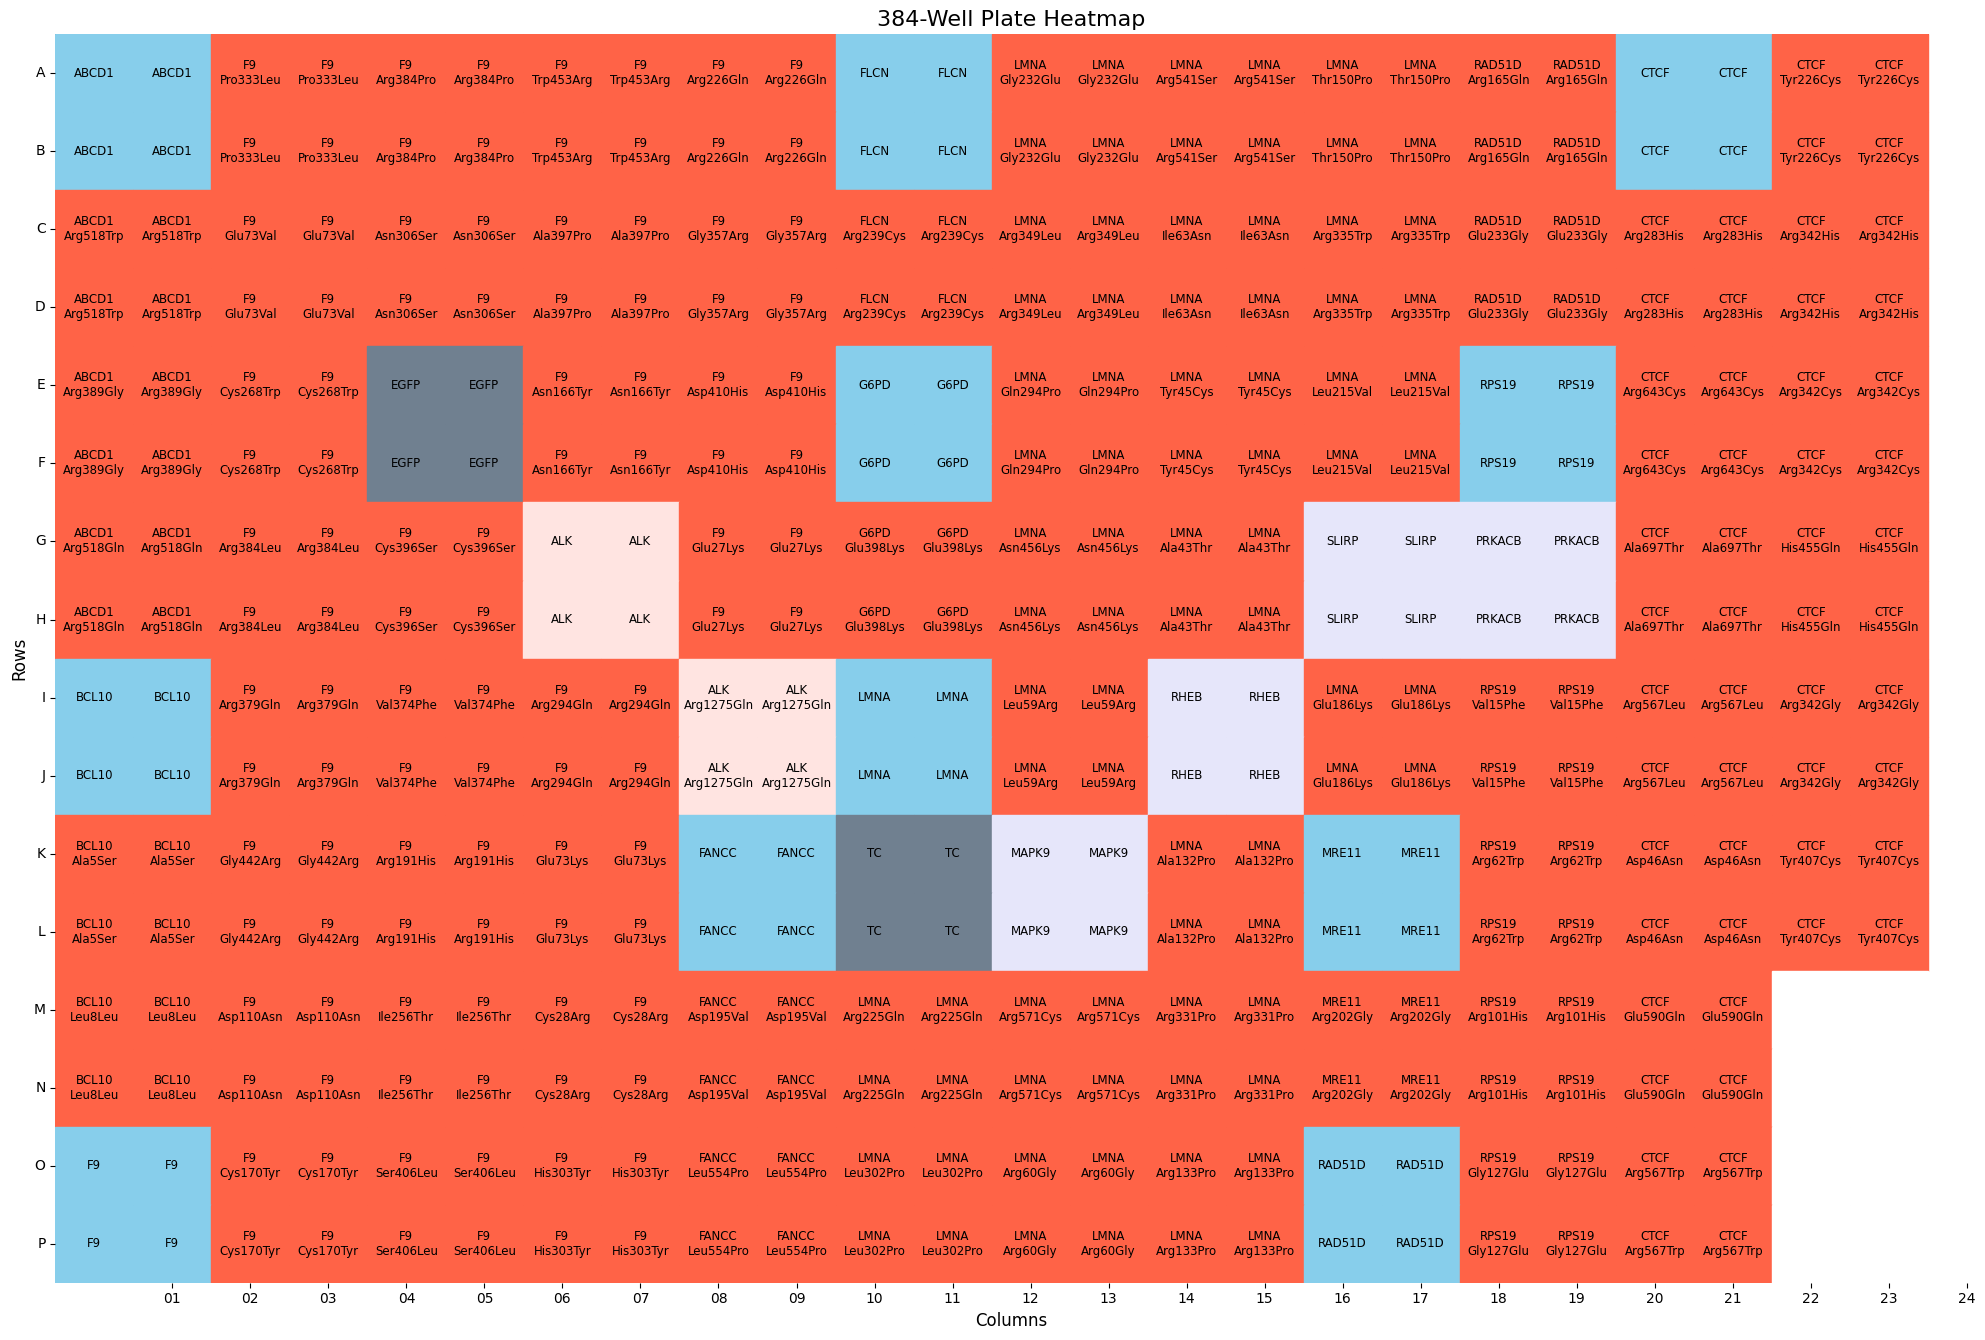

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P01""","""A01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T1""","""A01""",1,"""A01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,1,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
1,"""01""","""""","""B""","""01""","""P01""","""B01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T3""","""A01""",1,"""B01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,3,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
2,"""01""","""""","""C""","""01""","""P01""","""C01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T1""","""B01""",2,"""C01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
3,"""01""","""""","""D""","""01""","""P01""","""D01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T3""","""B01""",2,"""D01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",3,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
4,"""01""","""""","""E""","""01""","""P01""","""E01""","""ABCD1""","""ABCD1_Arg389Gly""","""CAVA_CP_P01_Prep2""","""C01""",3,"""CAVA_CP_Array_P01_T1""","""C01""",3,"""E01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007023""","""1165C>G""","""Arg389Gly""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg389Gly"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""","""P01""","""L24""","""CTCF""","""CTCF_Tyr407Cys""","""CAVA_CP_P02""","""H04""",32,"""CAVA_CP_Array_P01_T4""","""F12""",94,"""L24""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",6173,"""CCSBVarC010870""","""1220A>G""","""Tyr407Cys""",4,6,1,9,10,594,"""allele""","""allele""","""CTCF Tyr407Cys"""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [42]:
batch9_platemap_wf = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_widefield/platemap"
plate_map_id2 = "B9A6R1_P01_widefield.txt"
plate_map_2 = pl.read_csv(Path(batch9_platemap_wf) / Path(plate_map_id2), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map_2 = plate_map_2.filter(~pl.all_horizontal(pl.all().is_null()))
print(plate_map_2.shape)
column_name = "gene_allele"
plate_map_2 = plate_map_2.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)
# plate_map
# print(plate_map.select(pl.col(column_name).unique()))
# print(plate_map.select(pl.col("gene_allele").unique()))
# # print(plate_map.select(pl.col("symbol").unique()))
plot_platemap(plate_map_2)

In [193]:
# batch10_platemap_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_10_widefield/platemap"
# plate_map_id = "B10A6R2_P01_widefield.txt"
# plate_map = pl.read_csv(Path(batch10_platemap_dir) / Path(plate_map_id), separator='\t', has_header=True)
# plate_map = plate_map.drop_nulls()
# plate_map = plate_map.with_columns(pl.col("node_type").alias("control_type"))
# plot_platemap(plate_map)

## Batch 7/8

shape: (92, 1)
┌────────┐
│ symbol │
│ ---    │
│ str    │
╞════════╡
│ CTRC   │
│ BTC    │
│ EZH2   │
│ RHEB   │
│ ACY1   │
│ …      │
│ COL2A1 │
│ ANKRD1 │
│ ADIPOQ │
│ CREB1  │
│ AGXT   │
└────────┘


plate_map_name,well_position,control_type,symbol,gene_allele,…,c96,r96,r384,c384,r384_letter
str,str,str,str,str,…,i64,i64,i64,i64,str
"""B7A1R1_P1""","""A01""","""disease_wt""","""ACSF3""","""ACSF3""",…,1,1,1,1,"""A"""
"""B7A1R1_P1""","""C01""","""allele""","""ACSF3""","""ACSF3_Ala197Thr""",…,1,2,3,1,"""C"""
"""B7A1R1_P1""","""E01""","""allele""","""ACSF3""","""ACSF3_Thr358Ile""",…,1,3,5,1,"""E"""
"""B7A1R1_P1""","""G01""","""allele""","""ACSF3""","""ACSF3_Met198Arg""",…,1,4,7,1,"""G"""
"""B7A1R1_P1""","""I01""","""allele""","""ACSF3""","""ACSF3_Glu359Lys""",…,1,5,9,1,"""I"""
"""B7A1R1_P1""","""K01""","""allele""","""ACSF3""","""ACSF3_Ile200Met""",…,1,6,11,1,"""K"""
"""B7A1R1_P1""","""M01""","""allele""","""ACSF3""","""ACSF3_Ser431Tyr""",…,1,7,13,1,"""M"""
"""B7A1R1_P1""","""O01""","""allele""","""ACSF3""","""ACSF3_Gly225Arg""",…,1,8,15,1,"""O"""
"""B7A1R1_P1""","""A03""","""allele""","""ACSF3""","""ACSF3_Asp457Asn""",…,2,1,1,3,"""A"""


Number of unique alleles: ['AGXT_Met49Leu', 'ALAS2_Asp122Asn', 'ACSF3_Ile200Met', 'DES_Thr453Ile', 'DES_Met349Ile', 'AGXT_Arg301Cys', 'DES_Ala135Val', 'ADIPOQ', 'AGXT', 'AIPL1_Thr114Ile', 'AQP1', 'ACSF3', 'COMP_Asp319Val', 'AGXT_Ala186Val', 'CORO1A', 'ACSF3_Ser431Tyr', 'CYP21A2', 'AGXT_Ala85Asp', 'ALAS2_Ala135Thr', 'AGXT_Asp341Glu', 'ALAS2', 'COMP_Asp408Asn', 'DES_Ser46Tyr', 'BRIP1', 'EFHC1_Ile174Val', 'ALOX5', 'CTRC_Glu225Ala', 'AGXT_Arg197Gln', 'AGXT_Ala248Val', 'AIPL1_Met79Thr', 'CRYAB_Gly154Ser', 'AGXT_Asp129His', 'APOA1_Ala199Pro', 'EMD_Asp72Val', 'CBR3', 'ACSF3_Gly225Arg', 'DCX_Lys174Glu', 'AGXT_Ile202Asn', 'DES_Val56Leu', 'APOA1_Trp74Arg', 'AGXT_Leu298Pro', 'AGXT_Met195Leu', 'COMP_Thr585Met', 'DMC1', 'DCX_Arg89Gly', 'BLMH_Ile443Val', 'DES_Tyr331Asn', 'AMPD2', 'ACSF3_Arg558Trp', 'FADD_Cys105Trp', 'EMD_Met1Val', 'EIF2B4', 'ALAS2_Phe128Leu', 'DES_Pro433Thr', 'ACSF3_Ala197Thr', 'AGXT_Gly161Arg', 'DES_Gln389Pro', 'ACSF3_Arg471Trp', 'AGXT_Ser221Pro', 'EIF2B4_Ala228Val', 'ANKRD1', 'CLD

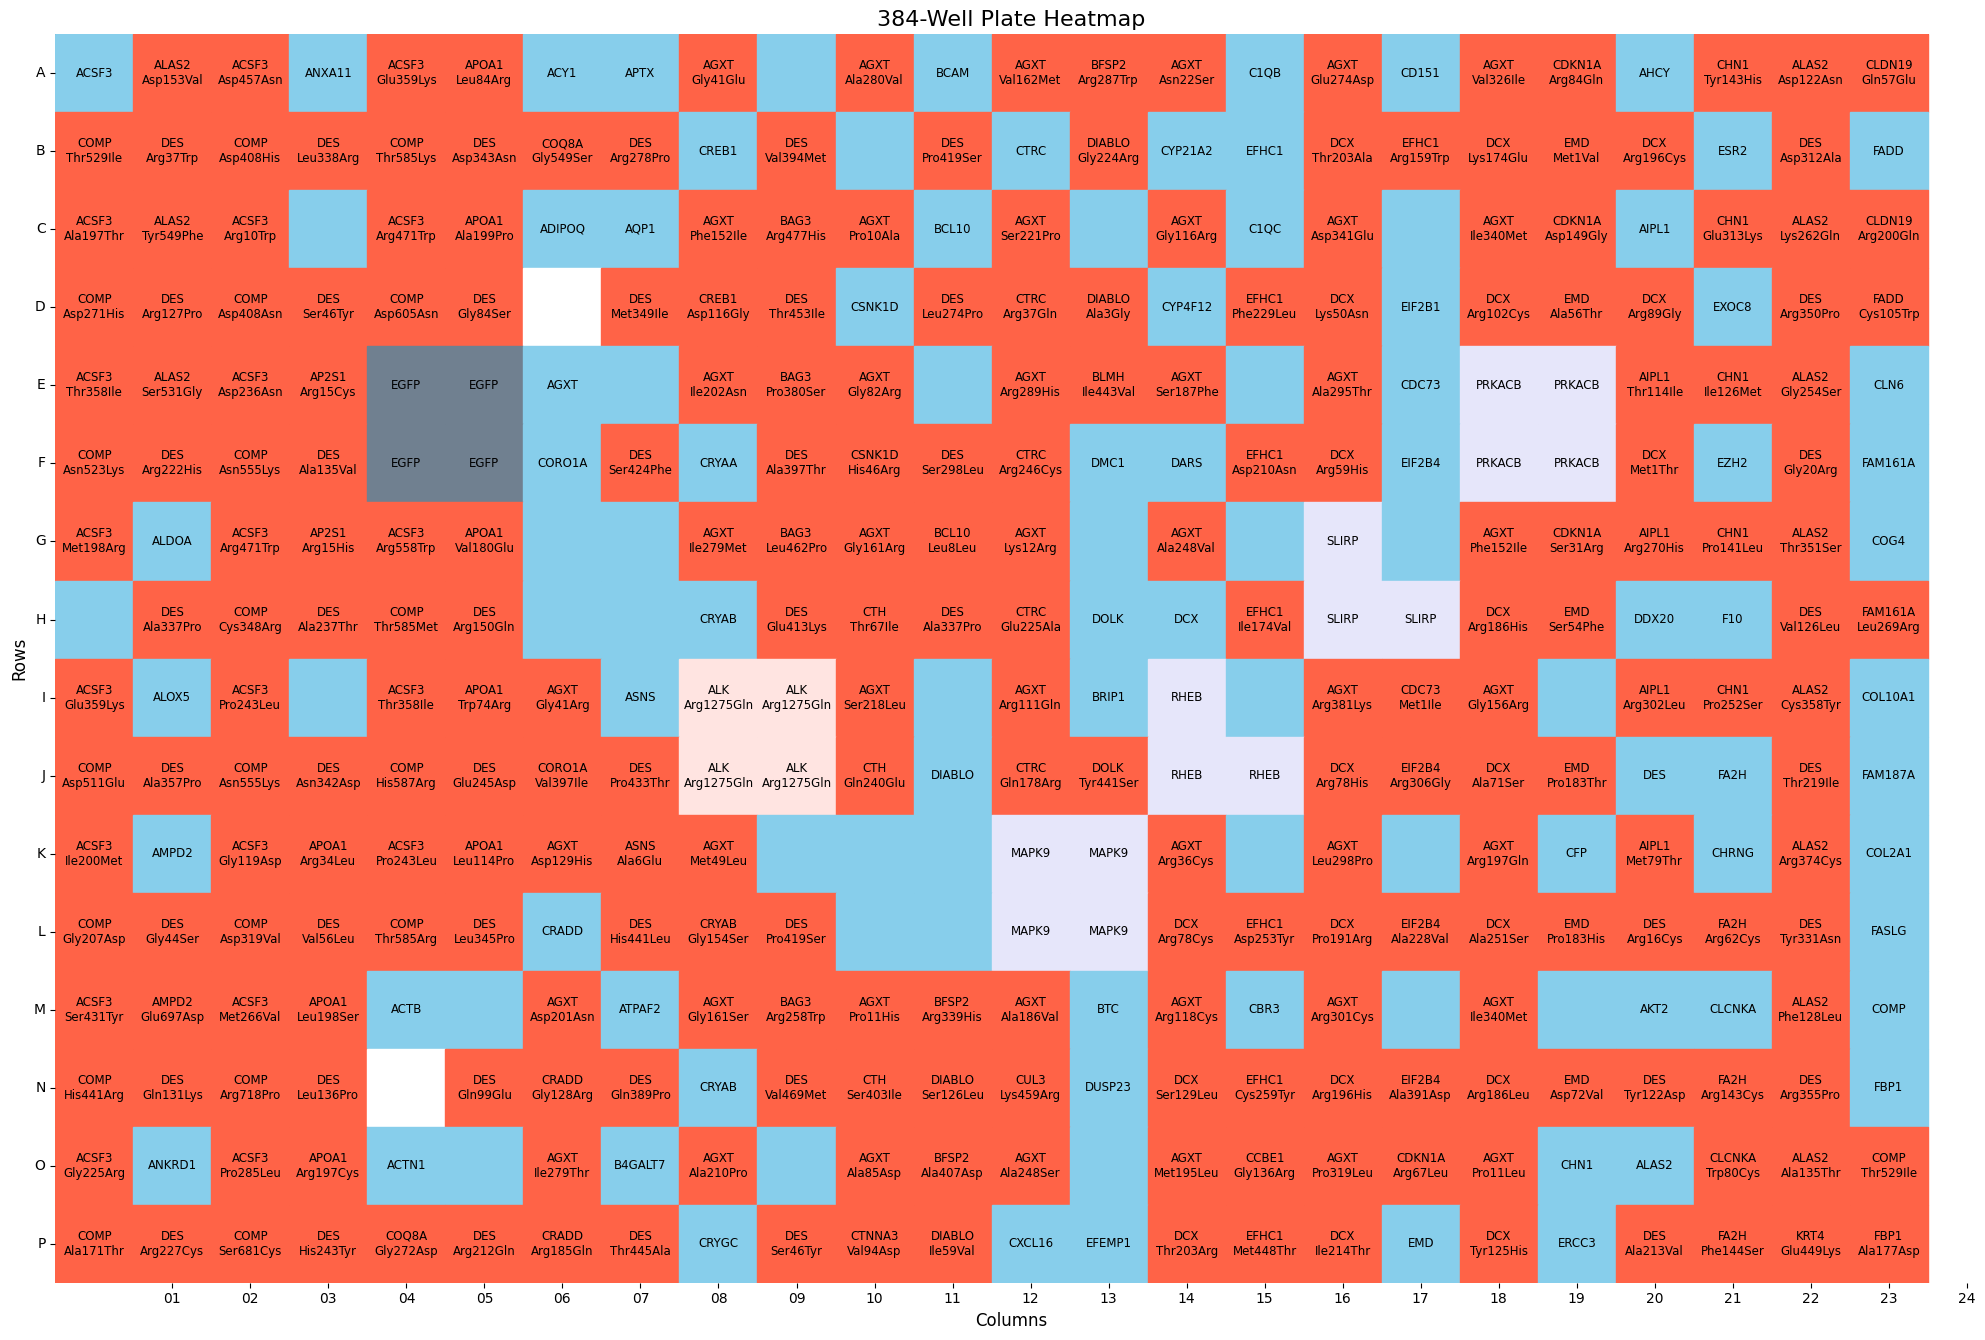

row,col,value,row_label,col_label,…,r384,c384,r384_letter,color,label
u64,str,str,str,str,…,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""",…,1,1,"""A""","""disease_wt""","""ACSF3"""
1,"""01""","""""","""B""","""01""",…,2,1,"""B""","""allele""","""COMP Thr529Ile"""
2,"""01""","""""","""C""","""01""",…,3,1,"""C""","""allele""","""ACSF3 Ala197Thr"""
3,"""01""","""""","""D""","""01""",…,4,1,"""D""","""allele""","""COMP Asp271His"""
4,"""01""","""""","""E""","""01""",…,5,1,"""E""","""allele""","""ACSF3 Thr358Ile"""
5,"""01""","""""","""F""","""01""",…,6,1,"""F""","""allele""","""COMP Asn523Lys"""
6,"""01""","""""","""G""","""01""",…,7,1,"""G""","""allele""","""ACSF3 Met198Arg"""
7,"""01""","""""","""H""","""01""",…,8,1,"""H""","""disease_wt""",""""""
8,"""01""","""""","""I""","""01""",…,9,1,"""I""","""allele""","""ACSF3 Glu359Lys"""


In [45]:
batch7_platemap_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch78/2024_01_23_Batch_7"
plate7_map_id = "B7A1R1_P1.txt"
plate7_map = pl.read_csv(Path(batch7_platemap_dir) / Path(plate7_map_id), separator='\t', has_header=True)
print(plate7_map.select(pl.col("symbol").unique()))

pl.Config.set_tbl_rows(200)  # Show all rows
pl.Config.set_tbl_cols(10)  # Show all columns
display(plate7_map)
# print("Number of unique alleles:", plate7_map.select(pl.col("gene_allele").unique()))
plate7_map.head() #  = plate_map.drop_nulls()
# print(plate7_map.filter(pl.col("symbol").is_in(TC+NC+PC+cNC+cPC) | pl.col("gene_allele").is_in(TC+NC+PC+cNC+cPC)))
# print(plate7_map.filter(pl.col("symbol").is_in(TC+NC+PC+cNC+cPC)))
plot_platemap(plate7_map)

In [34]:
# plate7_map.filter(pl.col("well_position")=="N05")